# Project 2.2 - Multimodal Movie Genre Classification

#### **Name**: Thanh Hien Tran
#### **Student ID:** a1948778
This notebook prepares the [Simplified MM-IMDb](https://www.kaggle.com/datasets/javierurea/simplified-mm-imdb)
 dataset for the individual implementation of Project 2.2(Ureña,2024).

The project uses two modalities:
- plot summaries as text data
- movie posters as image data

Before feature extraction and fusion, I first inspect the dataset structure and check basic data quality issues such as missing values, invalid labels and class imbalance.

In [1]:
# Import libraries for data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [3]:
# Load the movie records
data = np.load("data.npy", allow_pickle=True)
# Check the overall structure of the dataset
print("Data shape:", data.shape)
print("Data type:", data.dtype)

Data shape: (25959, 3)
Data type: object


The dataset contains 25959 movie records. Each record includes a movie ID, a 23-dimensional genre label vector and a plot summary. Since a movie can belong to more than one genre, this is a multi-label classification task.

## 1.Inspect the dataset structure

I inspect the first record to confirm how the movie ID, genre labels and plot summary are stored. Then, I separate these fields so they can be analysed individually.

In [7]:
# Inspect the first movie record
print("First record:")
print(data[0])

print("\nMovie ID:")
print(data[0][0])

print("\nGenre label vector:")
print(data[0][1])

print("\nPlot summary:")
print(data[0][2][:500])

First record:
[0
 list([1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1])
 "sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all . miss purvis wants protection . the police want answers . and all sorts of people want the ' french horn '

In [9]:
# Separate the three fields for easier analysis
movie_ids = data[:, 0]
labels = np.stack(data[:, 1]).astype(int)
plots = data[:, 2]
# Check the shape of each field
print("Movie IDs shape:", movie_ids.shape)
print("Labels shape:", labels.shape)
print("Plots shape:", plots.shape)

Movie IDs shape: (25959,)
Labels shape: (25959, 23)
Plots shape: (25959,)


The dataset has 25959 movie IDs, 25959 plot summaries and a 23-dimensional genre label vector for each movie. The matching number of records across these fields indicates that the text and labels are aligned row by row.

## 2.Check basic data quality

Before preprocessing, I check for common data quality issues in the movie records, including duplicate IDs, missing plot summaries, invalid genre labels and movies with no assigned genre.

In [13]:
# Check the number of records and unique movie IDs
print("Number of records:", len(data))
print("Unique movie IDs:", len(np.unique(movie_ids)))

# Check for missing or empty plot summaries
empty_plots = sum(
    not isinstance(plot, str) or plot.strip() == ""
    for plot in plots)

# Check that all genre labels are binary (0 or 1)
binary_labels = np.all(
    (labels == 0) | (labels == 1))

# Check whether any movie has no assigned genre
movies_without_genre = np.sum(
    labels.sum(axis=1) == 0)

# Display the data quality check results
print("Empty plot summaries:", empty_plots)
print("Labels are binary:", binary_labels)
print("Movies with no genre:", movies_without_genre)

Number of records: 25959
Unique movie IDs: 25959
Empty plot summaries: 0
Labels are binary: True
Movies with no genre: 0


The dataset contains 25959 unique movie records with no empty plot summaries. All genre labels are binary and every movie has at least one genre label. These checks indicate that the text and label data are complete and valid for the classification task.

## 3. Examine the multi-label distribution

I check how many genres are assigned to each movie. This helps confirm the multi-label nature of the dataset and shows how many labels each movie typically has.

In [17]:
# Count how many genres are assigned to each movie
genres_per_movie = labels.sum(axis=1)
# Calculate summary statistics for the number of genres per movie
print("Mean genres per movie:", round(genres_per_movie.mean(), 2))
print("Median genres per movie:", np.median(genres_per_movie))
print("Minimum genres per movie:", genres_per_movie.min())
print("Maximum genres per movie:", genres_per_movie.max())
# Calculate the percentage of movies with two or more genres
multi_label_percentage = np.mean(genres_per_movie >= 2) * 100
print("Movies with two or more genres:",round(multi_label_percentage, 2),"%")

Mean genres per movie: 2.48
Median genres per movie: 2.0
Minimum genres per movie: 1
Maximum genres per movie: 10
Movies with two or more genres: 77.02 %


Movies have an average of about 2.48 genres and around 77% of movies belong to at least two genres. This confirms that the dataset is appropriate for a multi-label classification task.

## 4. Check genre distribution and class imbalance

I examine how frequently each genre appears in the dataset. This helps identify whether some genres are much more common than others, which may affect model performance.

In [23]:
# Count how many movies belong to each genre
genre_counts = labels.sum(axis=0)

In [25]:
# Convert genre counts to percentages
genre_percentages = genre_counts / len(labels) * 100

# Genre names in the same order as the 23 label columns
genres = [
    "Drama", "Comedy", "Romance", "Thriller", "Crime", "Action","Adventure", 
    "Horror", "Documentary", "Mystery", "Sci-Fi","Fantasy", "Family", "Biography", "War", 
    "History", "Music","Animation", "Musical", "Western", "Sport", "Short", "Film-Noir"]

# Check the number of genre names matches the label columns
assert len(genres) == labels.shape[1]

# Display the count and percentage for each genre
for genre, count, percentage in zip(genres, genre_counts, genre_percentages):
    print(genre, int(count), f"{percentage:.2f}%")

Drama 13967 53.80%
Comedy 8592 33.10%
Romance 5364 20.66%
Thriller 5192 20.00%
Crime 3838 14.78%
Action 3550 13.68%
Adventure 2710 10.44%
Horror 2703 10.41%
Documentary 2082 8.02%
Mystery 2057 7.92%
Sci-Fi 1991 7.67%
Fantasy 1933 7.45%
Family 1668 6.43%
Biography 1343 5.17%
War 1335 5.14%
History 1143 4.40%
Music 1045 4.03%
Animation 997 3.84%
Musical 841 3.24%
Western 705 2.72%
Sport 634 2.44%
Short 471 1.81%
Film-Noir 338 1.30%


In [27]:
# Store the genre distribution in a dataframe
genre_df = pd.DataFrame({"Genre": genres,
                         "Count": genre_counts,
                         "Percentage": genre_percentages})
# Sort genres from most common to least common
genre_df = genre_df.sort_values("Percentage", ascending=False)
genre_df

,Genre,Count,Percentage
0,Drama,13967,53.804076
1,Comedy,8592,33.098347
2,Romance,5364,20.663354
3,Thriller,5192,20.000770
4,Crime,3838,14.784853
5,Action,3550,13.675411
6,Adventure,2710,10.439539
7,Horror,2703,10.412574
8,Documentary,2082,8.020340
9,Mystery,2057,7.924034


I store the genre counts and percentages in a dataframe and sort them from the most common to the least common genre. This makes the distribution easier to read and use for the bar chart

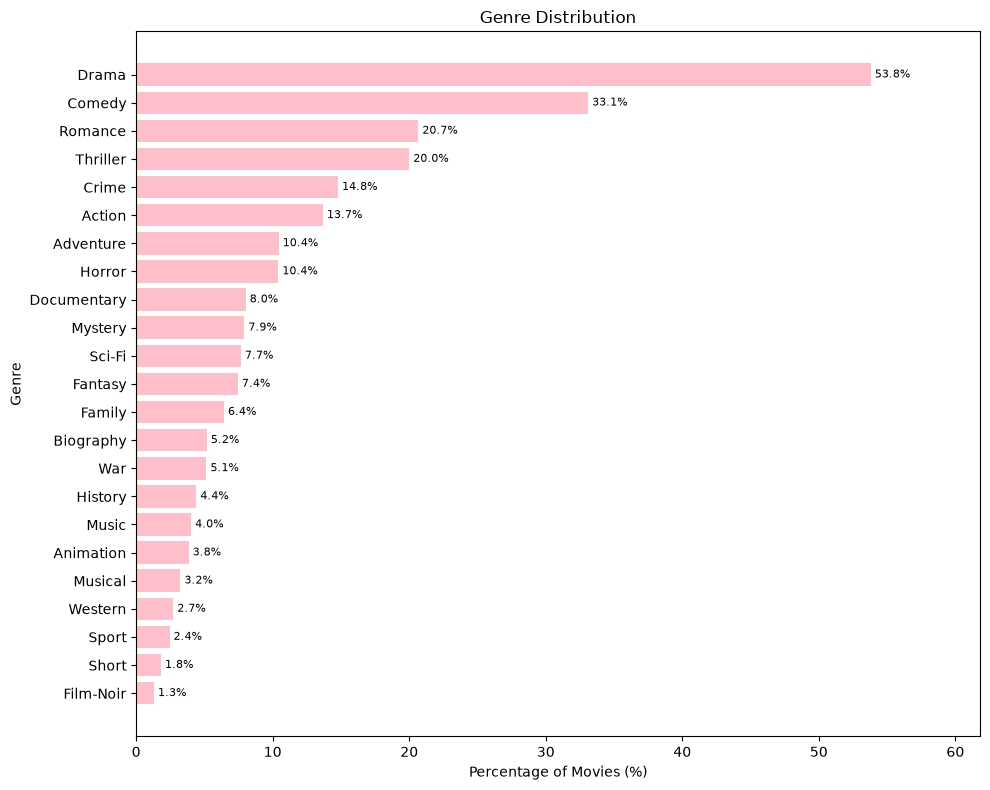

In [30]:
# Create a horizontal bar chart of genre frequencies
plt.figure(figsize=(10, 8))

bars = plt.barh(genre_df["Genre"],
                genre_df["Percentage"],
                color="pink")

plt.xlabel("Percentage of Movies (%)")
plt.ylabel("Genre")
plt.title("Genre Distribution")

# Keep the most common genre at the top
plt.gca().invert_yaxis()

# Leave some space for percentage labels
plt.xlim(0, max(genre_df["Percentage"]) + 8)

# Show the percentage next to each bar
for bar, percentage in zip(bars, genre_df["Percentage"]):
    plt.text(bar.get_width() + 0.3,
             bar.get_y() + bar.get_height() / 2,
             f"{percentage:.1f}%",
             va="center",
             fontsize=8)

plt.tight_layout()
plt.show()

The genre distribution is clearly imbalanced. Drama is the most common genre, appearing in 53.8% of movies, while Film-Noir is the least common at only 1.3%. Several genres such as Short, Sport and Western also have relatively few examples.

This imbalance may make the less frequent genres harder for the model to learn and predict compared with common genres. Therefore, I will later use Macro F1 and per-genre F1 to evaluate performance across all genres instead of only looking at overall performance.

## 5. Inspect the image modality

The second modality in this project is the movie poster image. Before image preprocessing, I inspect the image file structure, dimensions and pixel values and check whether the number of poster images matches the number of movie records.

In [34]:
# Load the poster image file
image_file = np.load("images.npz")

# Check what arrays are stored in the file
print("Keys in images.npz:", image_file.files)

Keys in images.npz: ['images']


In [36]:
# Extract the poster image array
images = image_file["images"]
print("Image array shape:", images.shape)
print("Image data type:", images.dtype)

Image array shape: (25959, 3, 256, 160)
Image data type: uint8


In [37]:
# Check whether every movie has a corresponding poster image
print("Number of movie records:", len(data))
print("Number of poster images:", len(images))
print("Record and image counts match:", len(data) == len(images))

Number of movie records: 25959
Number of poster images: 25959
Record and image counts match: True


In [38]:
# Check the range of pixel values
print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

Minimum pixel value: 0
Maximum pixel value: 255


The image file contains 25959 poster images, which matches the number of movie records in the dataset. Each image has shape 3x256x160, representing three colour channels with a height of 256 pixels and a width of 160 pixels.

The images are stored as `uint8`, with pixel values ranging from 0 to 255. This is the expected range for raw image data. The matching number of records and images also supports the expected row-wise alignment between the poster and plot modalities.

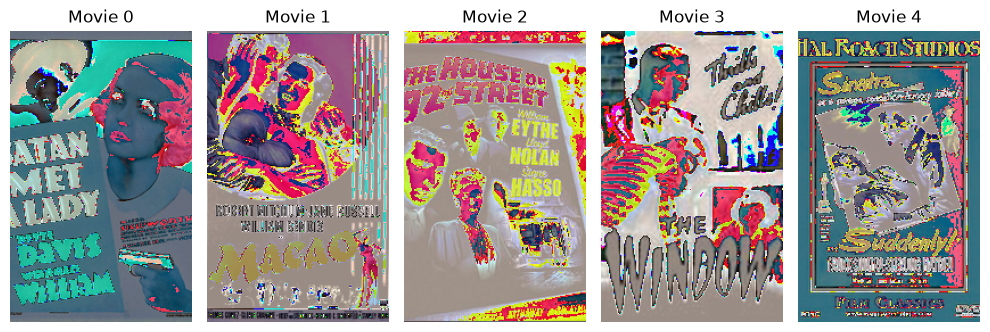

In [49]:
# Display a few poster samples
plt.figure(figsize=(10, 4))

for i in range(5):
    # Convert image from (C, H, W) to (H, W, C) for display
    poster = np.transpose(images[i], (1, 2, 0))

    plt.subplot(1, 5, i + 1)
    plt.imshow(poster)
    plt.axis("off")
    plt.title(f"Movie {movie_ids[i]}")

plt.tight_layout()
plt.show()

The sample posters can be displayed after converting the image arrays from `(C, H, W)` to `(H, W, C)`. The samples contain different visual information such as characters, text and poster layouts, showing that the image modality provides useful visual features for the movie genre classification task.

## 6. Check duplicate data

Before splitting the dataset, I check for duplicated plot summaries and poster images. Duplicate samples may cause data leakage if identical records appear across the training, validation and test sets

In [53]:
# Find duplicated plot summaries
plot_series = pd.Series(plots)
duplicate_plot_mask = plot_series.duplicated(keep=False)
duplicate_plot_count = duplicate_plot_mask.sum()
print("Rows with duplicated plot summaries:", duplicate_plot_count)

Rows with duplicated plot summaries: 25


In [55]:
# Count groups of duplicated plot summaries
duplicate_plot_groups = (plot_series[duplicate_plot_mask].value_counts())
print("Number of duplicate plot groups:", len(duplicate_plot_groups))

Number of duplicate plot groups: 11


In [57]:
# Display a few duplicated plot summaries
for summary, count in duplicate_plot_groups.head().items():
    print("Count:", count)
    print("Summary:", summary[:200], "...")
    print()

Count: 5
Summary: director ...

Count: 2
Summary: it ' s N . there are all sorts of aliens living throughout space . johnny is a space delivery man who travels to different planets to deliver packages . johnny is lazy and his only desire is to sleep  ...

Count: 2
Summary: an evil genius in a flying fortress is trying to kidnap the birds of the fire , ice , and lightning islands in hopes of luring the sea power , lugia , and controlling the world . ash and his friends , ...

Count: 2
Summary: germany N . middle aged dr . immanuel rath is a literature professor at a boys college . most of his students don ' t much like him , often calling him " unrath " - german for garbage . dr . rath lear ...

Count: 2
Summary: where the red fern grows is the heartwarming and adventurous tale for all ages about a young boy and his quest for his own red - bone hound hunting dogs . set in the ozark mountains during the great d ...



There are 25 movie records with duplicated plot summaries, forming 11 duplicate groups. This means that some records contain exactly the same plot text. These duplicates could cause data leakage if copies of the same summary are placed in different train, validation or test sets. Therefore, records from the same duplicate group should remain in the same split when the dataset is divided later.

Next, I check for duplicated poster images. Since each poster contains many pixel values, I first use the total pixel value to find possible duplicate candidates and then compare the images directly to confirm exact duplicates

In [61]:
# Calculate the total pixel value for each poster
image_pixel_sums = images.sum(axis=(1, 2, 3))

# Find pixel sums that appear more than once
sum_counts = pd.Series(image_pixel_sums).value_counts()
duplicate_sum_values = sum_counts[sum_counts > 1].index
print("Number of repeated pixel sums:", len(duplicate_sum_values))

Number of repeated pixel sums: 115


In [62]:
# Store groups of exactly duplicated poster images
duplicate_poster_groups = []
for pixel_sum in duplicate_sum_values:
    # Get indices of posters with the same pixel sum
    indices = np.where(image_pixel_sums == pixel_sum)[0]
    checked = set()

    for i in range(len(indices)):
        if indices[i] in checked:
            continue
        group = [indices[i]]

        for j in range(i + 1, len(indices)):
            if np.array_equal(images[indices[i]], images[indices[j]]):
                group.append(indices[j])
                checked.add(indices[j])
        if len(group) > 1:
            duplicate_poster_groups.append(group)

print("Number of duplicate poster groups:", len(duplicate_poster_groups))

Number of duplicate poster groups: 63


In [65]:
# Count how many movie records are involved in duplicate poster groups
duplicate_poster_rows = sum(len(group) for group in duplicate_poster_groups)
print("Rows with duplicated poster images:", duplicate_poster_rows)
print("Number of duplicate poster groups:", len(duplicate_poster_groups))

Rows with duplicated poster images: 151
Number of duplicate poster groups: 63


There are 151 movie records with duplicated poster images, forming 63 duplicate groups. This shows that the same poster image is used by multiple movie records.

These duplicates may cause data leakage if identical posters appear in different data splits. Therefore, records from the same poster duplicate group should remain in the same split during dataset splitting.

In [68]:
# Check whether duplicated plot groups have the same genre labels
plot_groups_with_different_labels = 0

for summary in duplicate_plot_groups.index:
    indices = np.where(plots == summary)[0]

    first_label = labels[indices[0]]

    same_labels = all(np.array_equal(first_label, labels[index])
                      for index in indices[1:])

    if not same_labels:
        plot_groups_with_different_labels += 1

print("Duplicate plot groups with different labels:",plot_groups_with_different_labels)

Duplicate plot groups with different labels: 4


4 duplicated plot groups have different genre labels. This shows that identical plot text does not always correspond to exactly the same genre combination, which adds some ambiguity to the classification task

In [71]:
# Display movie IDs from the first few duplicate poster groups
for group in duplicate_poster_groups[:5]:
    print("Movie IDs:", movie_ids[group])
    print("Number of copies:", len(group))
    print()

Movie IDs: [253 323 362 475 18365]
Number of copies: 5

Movie IDs: [353 360 18280 18327 18354]
Number of copies: 5

Movie IDs: [432 436 15608 18282]
Number of copies: 4

Movie IDs: [3099 11512 14995 17919]
Number of copies: 4

Movie IDs: [202 3842 20086]
Number of copies: 3



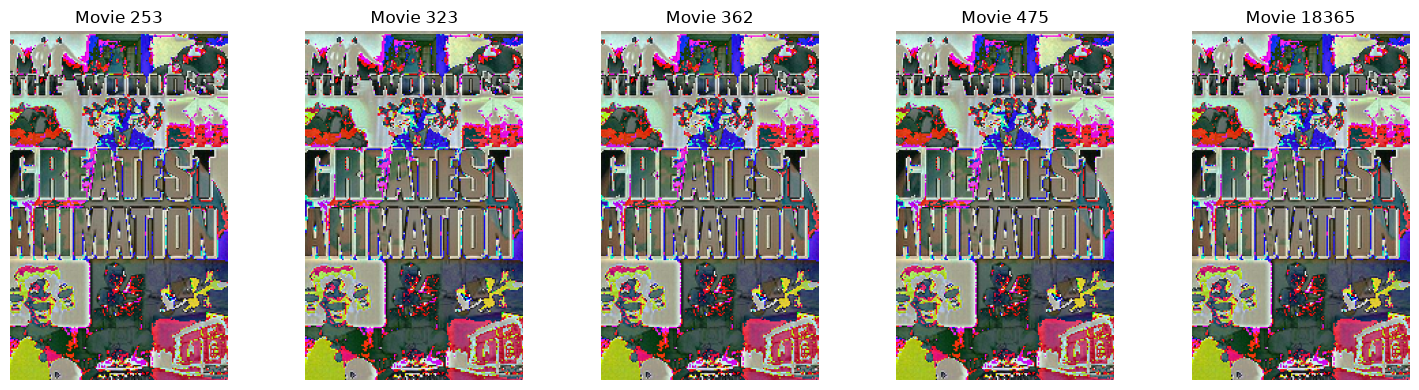

In [73]:
# Display posters from the first duplicate group
first_group = duplicate_poster_groups[0]

plt.figure(figsize=(3 * len(first_group), 4))

for i, index in enumerate(first_group):
    poster = np.transpose(images[index], (1, 2, 0))

    plt.subplot(1, len(first_group), i + 1)
    plt.imshow(poster)
    plt.title(f"Movie {movie_ids[index]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [75]:
# Check whether duplicated poster groups have the same genre labels
groups_with_different_labels = 0

for group in duplicate_poster_groups:
    first_label = labels[group[0]]
    same_labels = all(
        np.array_equal(first_label, labels[index])
        for index in group[1:])
    if not same_labels:
        groups_with_different_labels += 1

print("Duplicate poster groups with different labels:",groups_with_different_labels)

Duplicate poster groups with different labels: 39


Some duplicated poster groups have different genre labels. This means that the same poster image can be associated with different genre combinations so the image modality alone may not always provide enough information for genre prediction. This supports combining poster and plot information in the multimodal models.

## 7. Create train, validation and test splits

I keep the split design from the project proposal and ensure that records connected by duplicated plots or posters remain in the same split to reduce data leakage

In [79]:
# Start with each movie in its own group
group_ids = np.arange(len(data))

# Merge records that share the same duplicated plot summary
for summary in duplicate_plot_groups.index:
    indices = np.where(plots == summary)[0]

    current_groups = np.unique(group_ids[indices])
    new_group = current_groups.min()

    group_ids[np.isin(group_ids, current_groups)] = new_group

# Merge records that share the same duplicated poster image
for group in duplicate_poster_groups:
    current_groups = np.unique(group_ids[group])
    new_group = current_groups.min()

    group_ids[np.isin(group_ids, current_groups)] = new_group

print("Number of independent groups:", len(np.unique(group_ids)))

Number of independent groups: 25863


In [81]:
# Store the indices belonging to each group
all_groups = []

for group_id in np.unique(group_ids):
    indices = np.where(group_ids == group_id)[0]
    all_groups.append(indices)

# Separate duplicate-related groups from independent records
duplicate_groups = [group for group in all_groups
                    if len(group) > 1]

single_indices = np.array([group[0] for group in all_groups
                           if len(group) == 1])

print("Duplicate-related groups:", len(duplicate_groups))
print("Single records:", len(single_indices))

print("Total records:",sum(len(group) for group in duplicate_groups)+len(single_indices))

Duplicate-related groups: 68
Single records: 25795
Total records: 25959


In [83]:
# Keep the split sizes used in the project proposal
train_target = 15581
val_target = 2595
test_target = 7783

print("Training target:", train_target)
print("Validation target:", val_target)
print("Test target:", test_target)

print("Total target records:",train_target + val_target + test_target)

Training target: 15581
Validation target: 2595
Test target: 7783
Total target records: 25959


In [85]:
# Use a fixed random seed for reproducibility
random_seed = 42
rng = np.random.default_rng(random_seed)
print("Random seed:", random_seed)

# Shuffle the duplicate groups
rng.shuffle(duplicate_groups)

# Create empty split containers
split_indices = {"train": [],
                 "validation": [],
                 "test": []}

# Track how many records are still needed in each split
remaining = {"train": train_target,
             "validation": val_target,
             "test": test_target}
targets = {"train": train_target,
           "validation": val_target,
           "test": test_target}
# Assign each duplicate group to only one split
for group in duplicate_groups:

    possible_splits = [
        name for name in remaining
        if remaining[name] >= len(group)]

    # Choose the split with the largest remaining proportion
    selected_split = max(
        possible_splits,
        key=lambda name: remaining[name] / targets[name])

    split_indices[selected_split].extend(group)
    remaining[selected_split] -= len(group)

print("Remaining spaces after duplicate groups:")
print(remaining)

Random seed: 42
Remaining spaces after duplicate groups:
{'train': 15482, 'validation': 2578, 'test': 7735}


In [87]:
# Shuffle the independent records
rng.shuffle(single_indices)

start = 0
# Fill the remaining positions in each split
for split_name in ["train", "validation", "test"]:

    n_needed = remaining[split_name]

    selected_indices = single_indices[ start:start + n_needed]

    split_indices[split_name].extend(selected_indices)

    start += n_needed

In [89]:
# Convert the split indices to NumPy arrays
train_idx = np.array(split_indices["train"])
val_idx = np.array(split_indices["validation"])
test_idx = np.array(split_indices["test"])

# Shuffle the order within each split
rng.shuffle(train_idx)
rng.shuffle(val_idx)
rng.shuffle(test_idx)

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Test records:", len(test_idx))

Training records: 15581
Validation records: 2595
Test records: 7783


In [91]:
# Check the final split proportions
total_records = len(data)

print("Training:",
      len(train_idx),
      f"({len(train_idx) / total_records * 100:.2f}%)")

print("Validation:",
      len(val_idx),
      f"({len(val_idx) / total_records * 100:.2f}%)")

print("Test:",
      len(test_idx),
      f"({len(test_idx) / total_records * 100:.2f}%)")

Training: 15581 (60.02%)
Validation: 2595 (10.00%)
Test: 7783 (29.98%)


In [93]:
# Combine all split indices
all_split_indices = np.concatenate([train_idx,
                                    val_idx,
                                    test_idx])

# Check that every record appears exactly once
print("Total records in splits:", len(all_split_indices))
print("Unique records in splits:",len(np.unique(all_split_indices)))

all_records_once = (
    len(all_split_indices) == len(data)
    and len(np.unique(all_split_indices)) == len(data))
print("All records assigned exactly once:", all_records_once)

Total records in splits: 25959
Unique records in splits: 25959
All records assigned exactly once: True


In [95]:
# Record which split each movie belongs to
split_assignment = np.full(len(data), -1)

split_assignment[train_idx] = 0
split_assignment[val_idx] = 1
split_assignment[test_idx] = 2

# Check whether a duplicate-related group appears in multiple splits
overlapping_groups = 0

for group in duplicate_groups:

    group_splits = np.unique(split_assignment[group])

    if len(group_splits) > 1:
        overlapping_groups += 1

print("Duplicate groups appearing in more than one split:",overlapping_groups)

Duplicate groups appearing in more than one split: 0


In [97]:
# Calculate genre percentages in each split
overall_percentage = labels.mean(axis=0) * 100
train_percentage = labels[train_idx].mean(axis=0) * 100
val_percentage = labels[val_idx].mean(axis=0)* 100
test_percentage = labels[test_idx].mean(axis=0) * 100

# Store the split distributions in a dataframe
split_genre_df = pd.DataFrame({
    "Genre": genres,
    "Overall": overall_percentage,
    "Train": train_percentage,
    "Validation": val_percentage,
    "Test": test_percentage})
split_genre_df.round(2)

,Genre,Overall,Train,Validation,Test
0,Drama,53.80,53.66,54.72,53.80
1,Comedy,33.10,33.07,32.87,33.23
2,Romance,20.66,20.81,20.00,20.58
3,Thriller,20.00,19.77,19.46,20.65
4,Crime,14.78,14.72,15.45,14.69
5,Action,13.68,13.82,13.49,13.45
6,Adventure,10.44,10.37,10.91,10.42
7,Horror,10.41,10.16,10.21,10.99
8,Documentary,8.02,8.19,8.05,7.67
9,Mystery,7.92,7.68,8.25,8.31


In [99]:
# Check that all genres are represented in every split
print("All genres in training set:",
      np.all(labels[train_idx].sum(axis=0)> 0))

print("All genres in validation set:",
      np.all(labels[val_idx].sum(axis=0) > 0))

print("All genres in test set:",
      np.all(labels[test_idx].sum(axis=0) > 0))

All genres in training set: True
All genres in validation set: True
All genres in test set: True


In [101]:
# Save the split indices for later model experiments
np.savez( "split_indices.npz",
         train_idx=train_idx,
         val_idx=val_idx,
         test_idx=test_idx)

print("Split indices saved.")

Split indices saved.


The final dataset contains 15581 training records, 2595 validation records and 7783 test records. Every movie is assigned exactly once, and no duplicate-related group appears across multiple splits. All 23 genres are represented in each split, and the genre distributions remain reasonably similar to the overall dataset. The saved split indices will be reused for all model experiments to support a fair comparison

## 8. Text preprocessing for DistilBERT

I use the pretrained DistilBERT tokenizer to prepare the movie plot summaries for text feature extraction. DistilBERT is a smaller and faster version of BERT (Devlin et al., 2018; Sanh et al., 2019).

I load the `distilbert/distilbert-base-uncased` tokenizer from Hugging Face (Sanh et al., 2024) using the Transformers library (Wolf et al., 2020). I keep the maximum sequence length at 256 tokens, following our Project 2.1 proposal, and check how many plot summaries may require truncation.

### 8.1 Load the tokenizer

In [106]:
from transformers import AutoTokenizer

# Set the text model and maximum sequence length
text_model_name = "distilbert/distilbert-base-uncased"
max_length =256

# Load the pretrained tokenizer
tokenizer = AutoTokenizer.from_pretrained(text_model_name)
print("Text model:", text_model_name)
print("Maximum length:", max_length)
print("Tokenizer:", type(tokenizer).__name__)

Text model: distilbert/distilbert-base-uncased
Maximum length: 256
Tokenizer: BertTokenizer


### 8.2 Prepare text from the saved splits

In [108]:
# Select plot summaries using the indices from Part 7
train_texts = plots[train_idx].tolist()
val_texts = plots[val_idx].tolist()
test_texts = plots[test_idx].tolist()

# Check the number of texts in each split
print("Training texts:", len(train_texts))
print("Validation texts:", len(val_texts))
print("Test texts:", len(test_texts))

# Inspect one plot summary
print("\nSample plot summary:")
print(train_texts[0][:300])

Training texts: 15581
Validation texts: 2595
Test texts: 7783

Sample plot summary:
diane ' s free - wheeling life of drunken one - night - stands as a professional trucker hits a road block when peter , her son , is dropped at her doorstep . her former husband len , whom she abandoned eleven years ago along with their new - born son , has cancer and no one else to turn to while he


### 8.3 Inspect the tokenisation

In [112]:
# Tokenise one training plot summary
sample_text = train_texts[0]
sample_tokens = tokenizer.tokenize(sample_text)

print("Original text:")
print(sample_text[:300])
print("\nFirst 30 tokens:")
print(sample_tokens[:30])
print("\nNumber of tokens without special tokens:",len(sample_tokens))

Original text:
diane ' s free - wheeling life of drunken one - night - stands as a professional trucker hits a road block when peter , her son , is dropped at her doorstep . her former husband len , whom she abandoned eleven years ago along with their new - born son , has cancer and no one else to turn to while he

First 30 tokens:
['diane', "'", 's', 'free', '-', 'wheeling', 'life', 'of', 'drunken', 'one', '-', 'night', '-', 'stands', 'as', 'a', 'professional', 'truck', '##er', 'hits', 'a', 'road', 'block', 'when', 'peter', ',', 'her', 'son', ',', 'is']

Number of tokens without special tokens: 134


### 8.4 Check token lengths and truncation rate

In [118]:
# Calculate token lengths before truncation
token_lengths = []
batch_size = 128

for start in range(0, len(plots), batch_size):
    batch_texts = plots[start:start + batch_size].tolist()
    # Count tokens including special tokens
    encoded = tokenizer(batch_texts,
                        add_special_tokens=True,
                        padding=False,
                        truncation=False)
    for token_ids in encoded["input_ids"]:
        token_lengths.append(len(token_ids))

token_lengths = np.array(token_lengths)

# Check token length statistics
print("Mean token length:", round(token_lengths.mean(), 2))
print("Median token length:", np.median(token_lengths))
print("Minimum token length:", token_lengths.min())
print("Maximum token length:", token_lengths.max())

# Calculate how many summaries exceed the selected limit
truncated_count = np.sum(token_lengths > max_length)
truncation_rate = truncated_count / len(token_lengths) * 100
print("Plots exceeding 256 tokens:", truncated_count)
print("Truncation rate:", f"{truncation_rate:.2f}%")

Mean token length: 135.29
Median token length: 116.0
Minimum token length: 3
Maximum token length: 1999
Plots exceeding 256 tokens: 2668
Truncation rate: 10.28%


### 8.5 Visualise token length distribution

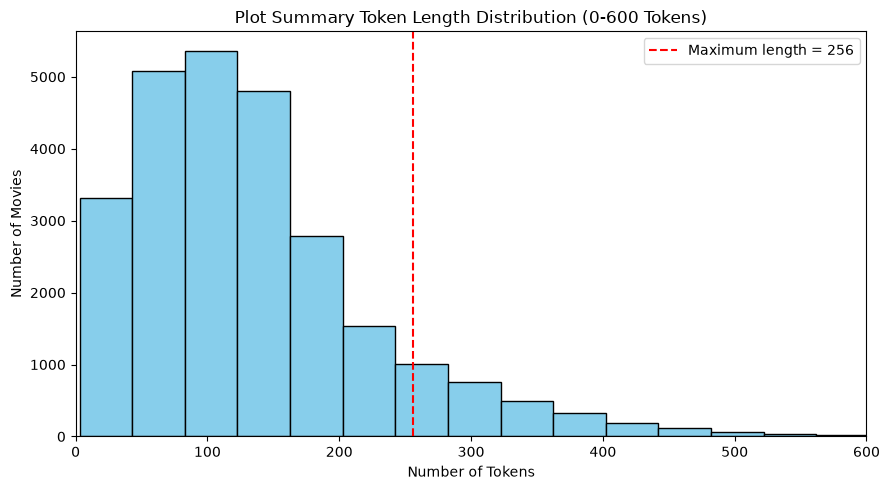

In [121]:
# Plot the token length distribution
plt.figure(figsize=(9, 5))
plt.hist(token_lengths, bins=50, color="skyblue", edgecolor="black")

# Show the selected maximum token length
plt.axvline(max_length,
            color="red",
            linestyle="--",
            label="Maximum length = 256")

plt.xlabel("Number of Tokens")
plt.ylabel("Number of Movies")
plt.title("Plot Summary Token Length Distribution (0-600 Tokens)")
plt.legend()
# Focus on the main token length range
plt.xlim(0, 600)
plt.tight_layout()
plt.show()

### 8.6 Apply padding and truncation

In [124]:
# Tokenise a small batch of training summaries
sample_batch = train_texts[:4]
encoded_batch = tokenizer(sample_batch,
                          padding="max_length",
                          truncation=True,
                          max_length=max_length,
                          return_tensors="pt")

# Check the tokenised input format
print("Input IDs shape:", encoded_batch["input_ids"].shape)
print("Attention mask shape:", encoded_batch["attention_mask"].shape)
print("\nFirst 20 input IDs:")
print(encoded_batch["input_ids"][0][:20])
print("\nFirst 20 attention mask values:")
print(encoded_batch["attention_mask"][0][:20])

Input IDs shape: torch.Size([4, 256])
Attention mask shape: torch.Size([4, 256])

First 20 input IDs:
tensor([  101, 12082,  1005,  1055,  2489,  1011, 29142,  2166,  1997, 15967,
         2028,  1011,  2305,  1011,  4832,  2004,  1037,  2658,  4744,  2121])

First 20 attention mask values:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


### 8.7 Verify the tokenised output

In [127]:
# Check the sequence length after preprocessing
correct_length = encoded_batch["input_ids"].shape[1] == max_length
print("Correct sequence length:", correct_length)

# Count non-padding tokens in each sample
actual_lengths = encoded_batch["attention_mask"].sum(dim=1)
print("Token counts after preprocessing:")
print(actual_lengths.tolist())

Correct sequence length: True
Token counts after preprocessing:
[136, 87, 43, 27]


### 8.8 Verify truncation on a long summary

In [130]:
# Find a plot summary that is longer than 256 tokens
long_index = np.where(token_lengths > max_length)[0][0]
long_text = plots[long_index]

# Tokenise the long summary with truncation
long_encoded = tokenizer(long_text,
                         padding="max_length",
                         truncation=True,
                         max_length=max_length,
                         return_tensors="pt")

# Compare the original and processed lengths
print("Movie ID:", movie_ids[long_index])
print("Original token length:", token_lengths[long_index])
print("Length after truncation:", long_encoded["input_ids"].shape[1])
print("Non-padding tokens:", long_encoded["attention_mask"].sum().item())

Movie ID: 2
Original token length: 269
Length after truncation: 256
Non-padding tokens: 256


##### Text preprocessing summary

The plot summaries have an average length of 135.29 tokens and a median length of 116 tokens. Using the 256-token limit, 2668 out of 25959 summaries (10.28%) require truncation. This matches the initial analysis in our Project 2.1 proposal.

The tokenisation results also confirm that padding and truncation work as expected. For example, a summary with 269 tokens was reduced to 256 tokens. I keep this setting for text feature extraction to maintain consistency with the proposal and reduce computational cost. However, truncation may remove useful information from longer plot summaries, which is a limitation of this preprocessing approach.

## 9. Image preprocessing for CLIP ViT-B/32

I prepare the movie poster images using the pretrained CLIP ViT-B/32 image processor. CLIP is used to extract visual features from the posters (Radford et al., 2021). I follow the preprocessing settings from Project 2.1, including resizing, centre cropping and normalisation to 224x224 pixels.

The image processor is loaded from Hugging Face (Openai/clip-vit-base-patch32, 2021) using the Transformers library (Wolf et al., 2020).

### 9.1 Load the CLIP image processor

In [140]:
from transformers import CLIPImageProcessor
# Set the pretrained CLIP model for poster images
image_model_name = "openai/clip-vit-base-patch32"

# Load the image processor from Hugging Face
image_processor = CLIPImageProcessor.from_pretrained(image_model_name)
print("Image model:", image_model_name)
print("Image processor:", type(image_processor).__name__)

# Check the preprocessing settings
print("Resize:", image_processor.size)
print("Centre crop:", image_processor.crop_size)
print("Normalisation mean:", image_processor.image_mean)
print("Normalisation std:", image_processor.image_std)

Image model: openai/clip-vit-base-patch32
Image processor: CLIPImageProcessor
Resize: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Centre crop: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Normalisation mean: (0.48145466, 0.4578275, 0.40821073)
Normalisation std: (0.26862954, 0.26130258, 0.27577711)


### 9.2 Prepare the poster images

In [143]:
# Check the stored image format
print("Image array shape:", images.shape)
print("Image data type:", images.dtype)

# Check poster counts in each split
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))

# Convert one poster from (C, H, W) to (H, W, C)
sample_index = train_idx[0]
sample_poster = np.transpose(images[sample_index], (1, 2, 0))

# Convert the NumPy array into a PIL image
sample_poster = Image.fromarray(sample_poster).convert("RGB")
print("Sample poster size:", sample_poster.size)
print("Sample poster mode:", sample_poster.mode)

Image array shape: (25959, 3, 256, 160)
Image data type: uint8
Training images: 15581
Validation images: 2595
Test images: 7783
Sample poster size: (160, 256)
Sample poster mode: RGB


### 9.3 Apply CLIP preprocessing to a small batch

In [146]:
# Select four training posters
sample_indices = train_idx[:4]
sample_images = []

for index in sample_indices:
    # Convert channel order for PIL
    poster = np.transpose(images[index], (1, 2, 0))
    poster = Image.fromarray(poster).convert("RGB")
    sample_images.append(poster)

# Apply CLIP preprocessing
processed_images = image_processor(images=sample_images,return_tensors="pt")

# Check the processed image tensor
pixel_values = processed_images["pixel_values"]
print("Pixel values shape:", pixel_values.shape)
print("Data type:", pixel_values.dtype)
print("Minimum value:", pixel_values.min().item())
print("Maximum value:", pixel_values.max().item())

Pixel values shape: torch.Size([4, 3, 224, 224])
Data type: torch.float32
Minimum value: -1.7922625541687012
Maximum value: 2.145897150039673


### 9.4 Visualise the original and processed posters

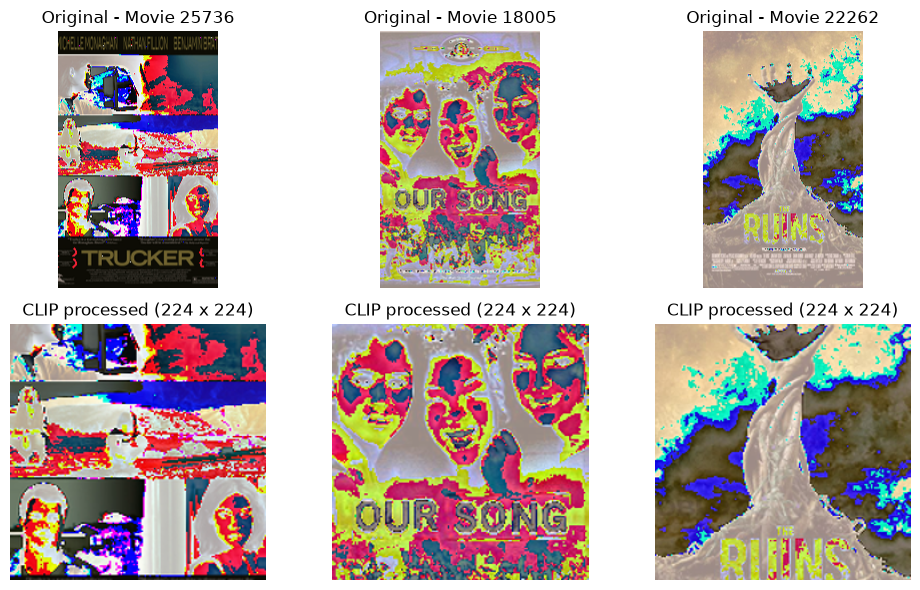

In [149]:
# Get the CLIP normalisation values
mean = np.array(image_processor.image_mean)
std = np.array(image_processor.image_std)
plt.figure(figsize=(10, 6))

for i in range(3):
    # Original poster
    plt.subplot(2, 3, i + 1)
    plt.imshow(sample_images[i])
    plt.title(f"Original - Movie {movie_ids[sample_indices[i]]}")
    plt.axis("off")

    # Convert the processed tensor for display
    processed = pixel_values[i].permute(1, 2, 0).numpy()

    # Undo normalisation for visualisation only
    processed = processed * std + mean
    processed = np.clip(processed, 0, 1)
    plt.subplot(2, 3, i + 4)
    plt.imshow(processed)
    plt.title("CLIP processed (224 x 224)")
    plt.axis("off")
plt.tight_layout()
plt.show()

### 9.5 Verify processed image dimensions

In [152]:
# Check the expected image shape for CLIP
correct_image_shape = pixel_values.shape ==(4, 3, 224, 224)
print("Correct processed image shape:", correct_image_shape)
# Check that the processed pixel values are finite
print("All pixel values are finite:",np.isfinite(pixel_values.numpy()).all())

Correct processed image shape: True
All pixel values are finite: True


In [154]:
# Check which image preprocessing steps are enabled
print("Resize enabled:", image_processor.do_resize)
print("Centre crop enabled:", image_processor.do_center_crop)
print("Rescale enabled:", image_processor.do_rescale)
print("Normalisation enabled:", image_processor.do_normalize)

Resize enabled: True
Centre crop enabled: True
Rescale enabled: True
Normalisation enabled: True


##### Image preprocessing summary

The movie posters were converted from the original `(3, 256, 160)` format into RGB PIL images and processed using the pretrained CLIP image processor. The output has the expected shape of `(4, 3, 224, 224)` and all processed pixel values are valid.

From the visual comparison, centre cropping removes some content from the top and bottom of the posters. This could affect genre prediction if useful visual details are lost. I follow the preprocessing settings from Project 2.1, including resizing, centre cropping to 224x224 pixels and pixel normalisation. However, the original colour channel order has not been confirmed so I keep the existing channel arrangement rather than changing it without evidence.

I retain the default CLIP preprocessing settings to stay consistent with the pretrained model and the Project 2.1 proposal

## 10. Feature extraction using DistilBERT and CLIP ViT-B/32

I use the pretrained DistilBERT and CLIP ViT-B/32 models to extract numerical features from the plot summaries and poster images. Both encoders are kept frozen so I can use the same extracted features to train and compare the different classification models.

DistilBERT provides text representations (Sanh et al., 2019), while CLIP provides visual representations from the movie posters (Radford et al., 2021). I extract features in batches to reduce memory usage and save them for later experiments.

### 10.1 Load models and select a device

In [159]:
import torch
from transformers import AutoModel, CLIPVisionModelWithProjection

# Check which device is available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

# Load the pretrained text and image encoders
text_model = AutoModel.from_pretrained(text_model_name)
image_model = CLIPVisionModelWithProjection.from_pretrained(image_model_name)

# Move both models to the selected device
text_model = text_model.to(device)
image_model = image_model.to(device)

# Use evaluation mode for feature extraction
text_model.eval()
image_model.eval()
print("Text model loaded:", text_model_name)
print("Image model loaded:", image_model_name)

Using device: cpu


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0

Text model loaded: distilbert/distilbert-base-uncased
Image model loaded: openai/clip-vit-base-patch32


In [161]:
# Check the loaded model types and feature dimensions
print("Text model type:", type(text_model).__name__)
print("Image model type:", type(image_model).__name__)

print("Text feature dimension:", text_model.config.dim)
print("Image feature dimension:", image_model.config.projection_dim)

print("Text model in evaluation mode:", not text_model.training)
print("Image model in evaluation mode:", not image_model.training)

Text model type: DistilBertModel
Image model type: CLIPVisionModelWithProjection
Text feature dimension: 768
Image feature dimension: 512
Text model in evaluation mode: True
Image model in evaluation mode: True


### 10.2 Extract text features from a small batch

In [164]:
# Select four training plot summaries
sample_texts = train_texts[:4]

# Tokenise the sample texts
text_inputs = tokenizer(sample_texts,
                        padding="max_length",
                        truncation=True,
                        max_length=max_length,
                        return_tensors="pt")

# Move the inputs to the selected device
text_inputs = {key: value.to(device)
               for key, value in text_inputs.items()}

# Extract text features without calculating gradients
with torch.inference_mode():
    text_outputs = text_model(**text_inputs)

    # Use the first token embedding to represent each plot
    sample_text_features = text_outputs.last_hidden_state[:, 0, :]
print("Text features shape:", sample_text_features.shape)
print("Text features data type:", sample_text_features.dtype)

# Check that all extracted values are valid
print("All values finite:",torch.isfinite(sample_text_features).all().item())

Text features shape: torch.Size([4, 768])
Text features data type: torch.float32
All values finite: True


### 10.3 Extract image features from a small batch

In [167]:
# Select four training poster images
sample_indices = train_idx[:4]
sample_images = []

for index in sample_indices:
    # Convert the poster from (C, H, W) to (H, W, C)
    poster = np.transpose(images[index], (1, 2, 0))
    poster = Image.fromarray(poster).convert("RGB")
    sample_images.append(poster)

# Apply the CLIP image preprocessing
image_inputs = image_processor(images=sample_images,return_tensors="pt")

# Move the image inputs to the selected device
image_inputs = {key: value.to(device)
                for key, value in image_inputs.items()}

# Extract image embeddings without calculating gradients
with torch.inference_mode():
    image_outputs = image_model(**image_inputs)
    sample_image_features = image_outputs.image_embeds
print("Image features shape:", sample_image_features.shape)
print("Image features data type:", sample_image_features.dtype)

# Check that the extracted values are valid
print("All values finite:",torch.isfinite(sample_image_features).all().item())

Image features shape: torch.Size([4, 512])
Image features data type: torch.float32
All values finite: True


### 10.4 Extract text features in batches

In [170]:
# Extract DistilBERT features in batches
def extract_text_features(texts, batch_size=8):
    features = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        # Tokenise the current batch
        inputs = tokenizer(batch_texts,
                           padding="max_length",
                           truncation=True,
                           max_length=max_length,
                           return_tensors="pt")

        # Move the inputs to the selected device
        inputs = {key: value.to(device)
                  for key, value in inputs.items()}

        # Extract embeddings without calculating gradients
        with torch.inference_mode():
            outputs = text_model(**inputs)
            batch_features = outputs.last_hidden_state[:, 0, :]
        # Store the features on CPU
        features.append(batch_features.cpu().numpy())

    return np.concatenate(features, axis=0)

In [172]:
# Test the function on eight training summaries
test_text_features = extract_text_features(train_texts[:8])
print("Test text features shape:", test_text_features.shape)
print("Data type:", test_text_features.dtype)

# Check that all values are finite
print("All values finite:", np.isfinite(test_text_features).all())

Test text features shape: (8, 768)
Data type: float32
All values finite: True


### 10.5 Extract and save text features

#### 10.5.1 Extract training text features

In [176]:
import time

# Extract DistilBERT features for the training set
start_time = time.perf_counter()
text_train_features = extract_text_features(train_texts)
train_text_time = time.perf_counter() - start_time

# Check the extracted training features
print("Training text features:", text_train_features.shape)
print("All values finite:", np.isfinite(text_train_features).all())
print("Extraction time (seconds):", round(train_text_time, 2))

# Save the training features
np.save("text_train_features.npy", text_train_features)
print("Training text features saved.")

Training text features: (15581, 768)
All values finite: True
Extraction time (seconds): 364.69
Training text features saved.


#### 10.5.2 Extract validation text features

In [179]:
# Extract DistilBERT features for the validation set
start_time = time.perf_counter()
text_val_features = extract_text_features(val_texts)
val_text_time = time.perf_counter() - start_time

# Check the extracted validation features
print("Validation text features:", text_val_features.shape)
print("All values finite:", np.isfinite(text_val_features).all())
print("Extraction time (seconds):", round(val_text_time, 2))

# Save the validation features
np.save("text_val_features.npy", text_val_features)
print("Validation text features saved.")

Validation text features: (2595, 768)
All values finite: True
Extraction time (seconds): 58.63
Validation text features saved.


#### 10.5.3 Extract test text features

In [182]:
# Extract DistilBERT features for the test set
start_time = time.perf_counter()
text_test_features = extract_text_features(test_texts)
test_text_time = time.perf_counter() - start_time

# Check the extracted test features
print("Test text features:", text_test_features.shape)
print("All values finite:", np.isfinite(text_test_features).all())
print("Extraction time (seconds):", round(test_text_time, 2))

# Save the test features
np.save("text_test_features.npy", text_test_features)
print("Test text features saved.")

Test text features: (7783, 768)
All values finite: True
Extraction time (seconds): 165.34
Test text features saved.


#### 10.5.4 Summarise the text feature extraction

In [185]:
# Calculate the total text feature extraction time
total_text_time = train_text_time + val_text_time + test_text_time
print("Training features:", text_train_features.shape)
print("Validation features:", text_val_features.shape)
print("Test features:", text_test_features.shape)
print("Total text extraction time (seconds):",round(total_text_time, 2))

# Check that all three sets contain valid features
all_text_valid = all(np.isfinite(features).all()
                     for features in [text_train_features,
                                      text_val_features,
                                      text_test_features])
print("All text features valid:", all_text_valid)

Training features: (15581, 768)
Validation features: (2595, 768)
Test features: (7783, 768)
Total text extraction time (seconds): 588.66
All text features valid: True


### 10.6 Extract and save image features

#### 10.6.1 Create the image feature extraction function

In [189]:
# Extract CLIP image features in batches
def extract_image_features(indices, batch_size=8):
    features = []

    for start in range(0, len(indices), batch_size):
        batch_indices = indices[start:start + batch_size]
        batch_images =[]

        # Convert the current posters to PIL images
        for index in batch_indices:
            poster = np.transpose(images[index], (1, 2, 0))
            poster = Image.fromarray(poster).convert("RGB")
            batch_images.append(poster)

        # Apply the CLIP image preprocessing
        inputs = image_processor(images=batch_images,return_tensors="pt")
        # Move the inputs to the selected device
        inputs = {key: value.to(device)
                  for key, value in inputs.items()}
        # Extract image embeddings without calculating gradients
        with torch.inference_mode():
            outputs = image_model(**inputs)
            batch_features = outputs.image_embeds

        # Store features on CPU
        features.append(batch_features.cpu().numpy())
    return np.concatenate(features, axis=0)

#### 10.6.2 Test the function on eight posters

In [192]:
# Test CLIP feature extraction on eight training posters
test_image_features = extract_image_features(train_idx[:8])
print("Test image features shape:", test_image_features.shape)
print("Data type:", test_image_features.dtype)

# Check that all values are finite
print("All values finite:", np.isfinite(test_image_features).all())

Test image features shape: (8, 512)
Data type: float32
All values finite: True


#### 10.6.3 Extract training image features

In [195]:
# Extract CLIP features for the training set
start_time = time.perf_counter()
image_train_features = extract_image_features(train_idx)
train_image_time = time.perf_counter() - start_time

# Check the extracted training features
print("Training image features:", image_train_features.shape)
print("All values finite:", np.isfinite(image_train_features).all())
print("Extraction time (seconds):", round(train_image_time, 2))

# Save the training image features
np.save("image_train_features.npy", image_train_features)
print("Training image features saved.")

Training image features: (15581, 512)
All values finite: True
Extraction time (seconds): 273.64
Training image features saved.


#### 10.6.4 Extract validation image features

In [197]:
# Extract CLIP features for the validation set
start_time = time.perf_counter()
image_val_features = extract_image_features(val_idx)
val_image_time = time.perf_counter() - start_time

# Check the extracted validation features
print("Validation image features:", image_val_features.shape)
print("All values finite:", np.isfinite(image_val_features).all())
print("Extraction time (seconds):", round(val_image_time, 2))

# Save the validation image features
np.save("image_val_features.npy", image_val_features)
print("Validation image features saved.")

Validation image features: (2595, 512)
All values finite: True
Extraction time (seconds): 45.11
Validation image features saved.


#### 10.6.5 Extract test image features

In [201]:
# Extract CLIP features for the test set
start_time = time.perf_counter()
image_test_features = extract_image_features(test_idx)
test_image_time = time.perf_counter() - start_time

# Check the extracted test features
print("Test image features:", image_test_features.shape)
print("All values finite:", np.isfinite(image_test_features).all())
print("Extraction time (seconds):", round(test_image_time, 2))

# Save the test image features
np.save("image_test_features.npy", image_test_features)
print("Test image features saved.")

Test image features: (7783, 512)
All values finite: True
Extraction time (seconds): 124.42
Test image features saved.


#### 10.6.6 Summarise image feature extraction

In [203]:
# Calculate the total CLIP feature extraction time
total_image_time = train_image_time + val_image_time + test_image_time
print("Training features:", image_train_features.shape)
print("Validation features:", image_val_features.shape)
print("Test features:", image_test_features.shape)
print("Total image extraction time (seconds):",round(total_image_time, 2))

# Check all image features
all_image_valid = all(np.isfinite(features).all()
                      for features in [image_train_features,
                                       image_val_features,
                                       image_test_features])
print("All image features valid:", all_image_valid)

Training features: (15581, 512)
Validation features: (2595, 512)
Test features: (7783, 512)
Total image extraction time (seconds): 443.17
All image features valid: True


### 10.7 Verify feature dimensions and alignment

In [207]:
# Check the dimensions of text and image features
print("Training:")
print("Text:", text_train_features.shape)
print("Image:", image_train_features.shape)

print("\nValidation:")
print("Text:", text_val_features.shape)
print("Image:", image_val_features.shape)

print("\nTest:")
print("Text:", text_test_features.shape)
print("Image:", image_test_features.shape)

# Check that text, image and genre labels have matching records
train_aligned = (len(text_train_features)==len(image_train_features)==len(labels[train_idx]))
val_aligned = (len(text_val_features) == len(image_val_features) == len(labels[val_idx]))
test_aligned = (len(text_test_features) == len(image_test_features) == len(labels[test_idx]))

print("\nTraining alignment:", train_aligned)
print("Validation alignment:", val_aligned)
print("Test alignment:", test_aligned)

Training:
Text: (15581, 768)
Image: (15581, 512)

Validation:
Text: (2595, 768)
Image: (2595, 512)

Test:
Text: (7783, 768)
Image: (7783, 512)

Training alignment: True
Validation alignment: True
Test alignment: True


#### 10.7.1 Verify the saved feature files

In [210]:
# Load the saved features to check reproducibility
saved_text_train = np.load("text_train_features.npy")
saved_image_train = np.load("image_train_features.npy")
print("Saved text features:", saved_text_train.shape)
print("Saved image features:", saved_image_train.shape)

# Compare the saved features with the original arrays
print("Text saved correctly:",np.array_equal(saved_text_train, text_train_features))
print("Image saved correctly:",np.array_equal(saved_image_train, image_train_features))

Saved text features: (15581, 768)
Saved image features: (15581, 512)
Text saved correctly: True
Image saved correctly: True


### 10.8 Summarise feature extraction

In [213]:
# Summarise text and image feature extraction
feature_summary=pd.DataFrame({"Modality": ["Text", "Image"],
                              "Model": [text_model_name, image_model_name],
                              "Feature dimension": [768, 512],
                              "Training records": [len(text_train_features), len(image_train_features)],
                              "Validation records": [len(text_val_features), len(image_val_features)],
                              "Test records": [len(text_test_features), len(image_test_features)],
                              "Extraction time (s)":[round(total_text_time, 2),round(total_image_time, 2)]})

feature_summary

,Modality,Model,Feature dimension,Training records,Validation records,Test records,Extraction time (s)
0,Text,distilbert/distilbert-base-uncased,768,15581,2595,7783,588.66
1,Image,openai/clip-vit-base-patch32,512,15581,2595,7783,443.17


#### Feature extraction summary

I extracted 768-dimensional text embeddings using DistilBERT and 512-dimensional image embeddings using CLIP ViT-B/32. Both pretrained models were kept in evaluation mode, and the features were extracted in batches without updating the model weights.

The total extraction time was 588.66 seconds for text and 443.17 seconds for images on CPU. All extracted features contained valid values and were saved separately for the training, validation and test sets.

I used the same split indices for both modalities to keep the text features, image features and genre labels in the same order. These saved embeddings will be used to compare the unimodal and multimodal classification models.

## 11. Train and evaluate unimodal classification baselines

I train two unimodal classifiers using the saved DistilBERT text features and CLIP image features. Each model uses an MLP to predict 23 movie genres.

Since a movie can have multiple genres, I use sigmoid outputs and binary cross-entropy loss. I compare both models using Micro F1 and Macro F1 and monitor the training and validation losses to check for overfitting.

In [217]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
import copy

# Set a random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Prepare genre labels using the saved split indices
y_train = labels[train_idx].astype(np.float32)
y_val = labels[val_idx].astype(np.float32)
y_test = labels[test_idx].astype(np.float32)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

# Check the saved feature dimensions
print("Text training features:", text_train_features.shape)
print("Image training features:", image_train_features.shape)

Training labels: (15581, 23)
Validation labels: (2595, 23)
Test labels: (7783, 23)
Text training features: (15581, 768)
Image training features: (15581, 512)


### 11.2 Define the MLP classifier

In [220]:
# Define a simple MLP classifier
class GenreClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(nn.LayerNorm(input_dim),
                                   nn.Linear(input_dim, 256),
                                   nn.ReLU(),
                                   nn.Dropout(0.3),
                                   nn.Linear(256, 23))

    def forward(self, x):
        return self.model(x)
# Create both unimodal models
text_classifier = GenreClassifier(input_dim=768).to(device)
image_classifier = GenreClassifier(input_dim=512).to(device)
print("Text classifier:")
print(text_classifier)
print("\nImage classifier:")
print(image_classifier)

Text classifier:
GenreClassifier(
  (model): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=23, bias=True)
  )
)

Image classifier:
GenreClassifier(
  (model): Sequential(
    (0): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=512, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=23, bias=True)
  )
)


### 11.3 Prepare the DataLoaders

In [223]:
# Convert NumPy arrays into PyTorch tensors
def create_dataloader(features, targets, batch_size=64, shuffle=False):

    x = torch.tensor(features, dtype=torch.float32)
    y = torch.tensor(targets, dtype=torch.float32)

    dataset = TensorDataset(x, y)

    return DataLoader(dataset,
                      batch_size=batch_size,
                      shuffle=shuffle)


# Text DataLoaders
text_train_loader = create_dataloader(text_train_features, y_train, shuffle=True)
text_val_loader = create_dataloader(text_val_features, y_val)
text_test_loader = create_dataloader(text_test_features, y_test)

# Image DataLoaders
image_train_loader = create_dataloader(image_train_features, y_train, shuffle=True)
image_val_loader = create_dataloader(image_val_features, y_val)
image_test_loader = create_dataloader(image_test_features, y_test)
print("Text training batches:", len(text_train_loader))
print("Image training batches:", len(image_train_loader))

Text training batches: 244
Image training batches: 244


### 11.4 Define the training and validation functions

#### 11.4.1 Training function

In [227]:
# Train the classifier for one epoch
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0

    for features, targets in loader:
        features = features.to(device)
        targets = targets.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass and calculate loss
        outputs = model(features)
        loss = criterion(outputs, targets)

        # Backpropagation and update model weights
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(features)
    return total_loss / len(loader.dataset)

#### 11.4.2 Validation function

In [230]:
# Evaluate the classifier without updating weights
def evaluate_model(model, loader, criterion):
    model.eval()

    total_loss = 0
    all_targets = []
    all_probabilities = []

    with torch.inference_mode():
        for features, targets in loader:
            features = features.to(device)
            targets = targets.to(device)

            outputs = model(features)
            loss = criterion(outputs, targets)

            # Convert logits into probabilities
            probabilities = torch.sigmoid(outputs)

            total_loss += loss.item() * len(features)
            all_targets.append(targets.cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())

    all_targets = np.concatenate(all_targets, axis=0)
    all_probabilities = np.concatenate(all_probabilities, axis=0)

    # Use a fixed threshold of 0.5 for the initial baselines
    predictions = (all_probabilities >= 0.5).astype(int)

    micro_f1 = f1_score(all_targets, predictions,average="micro", zero_division=0)
    macro_f1 = f1_score(all_targets, predictions,average="macro", zero_division=0)

    average_loss = total_loss / len(loader.dataset)

    return average_loss, micro_f1, macro_f1

### 11.5 Train the text-only and image-only models

#### 11.5.1 Training loop

In [234]:
# Train a model and save its best validation result
def train_classifier(model, train_loader, val_loader, epochs=20):

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    val_losses = []
    val_micro_scores = []
    val_macro_scores = []

    best_macro_f1 = -1
    best_epoch = 0
    best_weights = None

    for epoch in range(epochs):

        # Train the model
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)

        # Evaluate on the validation set
        val_loss, micro_f1, macro_f1 = evaluate_model(model, val_loader, criterion)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_micro_scores.append(micro_f1)
        val_macro_scores.append(macro_f1)

        # Keep the model with the highest validation Macro F1
        if macro_f1 > best_macro_f1:
            best_macro_f1 = macro_f1
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Micro F1: {micro_f1:.4f} | "
            f"Macro F1: {macro_f1:.4f}")

    # Restore the best model weights
    model.load_state_dict(best_weights)

    history = {"train_loss": train_losses,
               "val_loss": val_losses,
               "val_micro_f1": val_micro_scores,
               "val_macro_f1": val_macro_scores}
    print("Best epoch:", best_epoch)
    print("Best validation Macro F1:", round(best_macro_f1, 4))
    return model, history, best_epoch

#### 11.5.2 Train the text-only model

In [237]:
# Train the text-only classifier
start_time = time.perf_counter()

text_classifier, text_history, text_best_epoch = train_classifier(text_classifier,
                                                                  text_train_loader,
                                                                  text_val_loader,
                                                                  epochs=20)

text_training_time = time.perf_counter() - start_time

# Save the trained classifier
torch.save(text_classifier.state_dict(), "text_classifier.pth")
print("Text model training time (s):", round(text_training_time, 2))
print("Text classifier saved")

Epoch 1/20 | Train loss: 0.2371 | Val loss: 0.1986 | Micro F1: 0.5159 | Macro F1: 0.3265
Epoch 2/20 | Train loss: 0.1966 | Val loss: 0.1898 | Micro F1: 0.5629 | Macro F1: 0.3942
Epoch 3/20 | Train loss: 0.1896 | Val loss: 0.1847 | Micro F1: 0.5838 | Macro F1: 0.4270
Epoch 4/20 | Train loss: 0.1859 | Val loss: 0.1815 | Micro F1: 0.5791 | Macro F1: 0.4363
Epoch 5/20 | Train loss: 0.1833 | Val loss: 0.1805 | Micro F1: 0.5892 | Macro F1: 0.4484
Epoch 6/20 | Train loss: 0.1812 | Val loss: 0.1803 | Micro F1: 0.5884 | Macro F1: 0.4558
Epoch 7/20 | Train loss: 0.1790 | Val loss: 0.1786 | Micro F1: 0.6001 | Macro F1: 0.4716
Epoch 8/20 | Train loss: 0.1770 | Val loss: 0.1783 | Micro F1: 0.6030 | Macro F1: 0.4695
Epoch 9/20 | Train loss: 0.1755 | Val loss: 0.1776 | Micro F1: 0.6096 | Macro F1: 0.4811
Epoch 10/20 | Train loss: 0.1742 | Val loss: 0.1779 | Micro F1: 0.6027 | Macro F1: 0.4816
Epoch 11/20 | Train loss: 0.1725 | Val loss: 0.1778 | Micro F1: 0.6004 | Macro F1: 0.4780
Epoch 12/20 | Train

#### 11.5.3 Train the image-only model

In [239]:
# Train the image-only classifier
start_time = time.perf_counter()
image_classifier, image_history, image_best_epoch = train_classifier(image_classifier,
                                                                     image_train_loader,
                                                                     image_val_loader,
                                                                     epochs=20)

image_training_time = time.perf_counter() - start_time
# Save the trained classifier
torch.save(image_classifier.state_dict(), "image_classifier.pth")
print("Image model training time (s):", round(image_training_time, 2))
print("Image classifier saved.")

Epoch 1/20 | Train loss: 0.2814 | Val loss: 0.2610 | Micro F1: 0.3404 | Macro F1: 0.0799
Epoch 2/20 | Train loss: 0.2568 | Val loss: 0.2566 | Micro F1: 0.3048 | Macro F1: 0.0998
Epoch 3/20 | Train loss: 0.2514 | Val loss: 0.2555 | Micro F1: 0.3778 | Macro F1: 0.1067
Epoch 4/20 | Train loss: 0.2481 | Val loss: 0.2543 | Micro F1: 0.3716 | Macro F1: 0.1285
Epoch 5/20 | Train loss: 0.2447 | Val loss: 0.2536 | Micro F1: 0.3598 | Macro F1: 0.1387
Epoch 6/20 | Train loss: 0.2410 | Val loss: 0.2541 | Micro F1: 0.3724 | Macro F1: 0.1424
Epoch 7/20 | Train loss: 0.2382 | Val loss: 0.2541 | Micro F1: 0.3941 | Macro F1: 0.1474
Epoch 8/20 | Train loss: 0.2346 | Val loss: 0.2557 | Micro F1: 0.3654 | Macro F1: 0.1525
Epoch 9/20 | Train loss: 0.2305 | Val loss: 0.2556 | Micro F1: 0.3692 | Macro F1: 0.1683
Epoch 10/20 | Train loss: 0.2268 | Val loss: 0.2574 | Micro F1: 0.3609 | Macro F1: 0.1509
Epoch 11/20 | Train loss: 0.2224 | Val loss: 0.2592 | Micro F1: 0.3890 | Macro F1: 0.1613
Epoch 12/20 | Train

### 11.6 Visualise training and validation results

#### 11.6.1 Plot training and validation loss

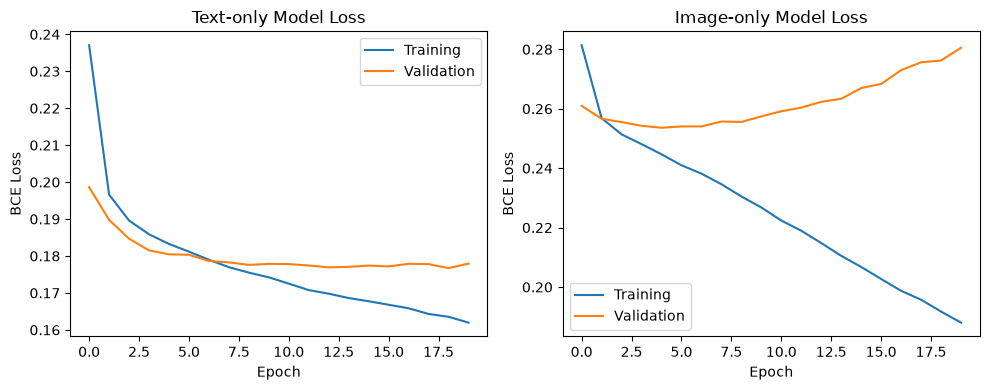

In [244]:
# Plot the loss curves for both classifiers
plt.figure(figsize=(10, 4))

# Text-only loss
plt.subplot(1, 2, 1)
plt.plot(text_history["train_loss"], label="Training")
plt.plot(text_history["val_loss"], label="Validation")
plt.title("Text-only Model Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()

# Image-only loss
plt.subplot(1, 2, 2)
plt.plot(image_history["train_loss"], label="Training")
plt.plot(image_history["val_loss"], label="Validation")
plt.title("Image-only Model Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()

plt.tight_layout()
plt.show()

#### 11.6.2 Plot validation F1 scores

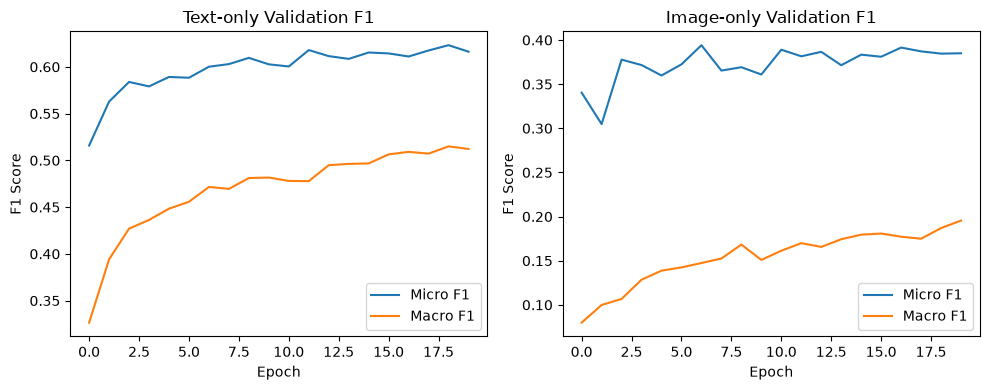

In [247]:
# Compare validation F1 scores across epochs
plt.figure(figsize=(10, 4))

# Text-only
plt.subplot(1, 2, 1)
plt.plot(text_history["val_micro_f1"], label="Micro F1")
plt.plot(text_history["val_macro_f1"], label="Macro F1")
plt.title("Text-only Validation F1")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.legend()

# Image-only
plt.subplot(1, 2, 2)
plt.plot(image_history["val_micro_f1"], label="Micro F1")
plt.plot(image_history["val_macro_f1"], label="Macro F1")
plt.title("Image-only Validation F1")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.legend()

plt.tight_layout()
plt.show()

### 11.7 Evaluate the selected models on the test set

In [250]:
# Evaluate the selected classifiers on the test set
criterion = nn.BCEWithLogitsLoss()

text_test_loss, text_micro_f1, text_macro_f1 = evaluate_model(
    text_classifier, text_test_loader, criterion)

image_test_loss, image_micro_f1, image_macro_f1 = evaluate_model(
    image_classifier, image_test_loader, criterion)

# Compare the two unimodal models
baseline_results = pd.DataFrame({
    "Model": ["Text-only", "Image-only"],
    "Test Loss": [text_test_loss, image_test_loss],
    "Micro F1": [text_micro_f1, image_micro_f1],
    "Macro F1": [text_macro_f1, image_macro_f1],
    "Training Time (s)": [text_training_time, image_training_time]})
baseline_results.round(4)

,Model,Test Loss,Micro F1,Macro F1,Training Time (s)
0,Text-only,0.1801,0.616,0.5078,9.4370
1,Image-only,0.2840,0.383,0.1874,9.0924


In [252]:
# Save the baseline comparison results
baseline_results.to_csv("unimodal_baseline_results.csv", index=False)
print("Baseline results saved.")

Baseline results saved.


#### Unimodal baseline results
The text-only model performed better than the image-only model on the test set. DistilBERT achieved a Micro F1 of 0.616 and Macro F1 of 0.5078, while CLIP achieved 0.3830 and 0.1874, respectively.

The training curves also show that the image-only model had stronger signs of overfitting, as its training loss decreased while validation loss increased. In comparison, the text-only model had a more stable validation loss.

These results suggest that plot summaries provide more useful information for genre classification in this dataset. However, the image features may still provide complementary information when combined with text through multimodal fusion.

### 11.8 Evaluate performance for each genre

I compare the performance of both unimodal models across the 23 movie genres. This helps identify which genres are more difficult to predict and whether the class imbalance affects the results.

In [258]:
from sklearn.metrics import precision_recall_fscore_support
# Get predictions from the selected model
def get_predictions(model, loader):
    model.eval()
    predictions = []

    with torch.inference_mode():
        for features, targets in loader:
            features = features.to(device)
            outputs = model(features)
            probabilities = torch.sigmoid(outputs)

            # Convert probabilities into binary genre predictions
            batch_predictions = (probabilities >= 0.5).int()
            predictions.append(batch_predictions.cpu().numpy())

    return np.concatenate(predictions, axis=0)

# Get test predictions for both unimodal models
text_predictions = get_predictions(text_classifier, text_test_loader)
image_predictions = get_predictions(image_classifier, image_test_loader)

# Calculate precision, recall and F1 for each genre
text_precision, text_recall, text_f1, support = precision_recall_fscore_support(
    y_test, text_predictions, average=None, zero_division=0)

image_precision, image_recall, image_f1, _ = precision_recall_fscore_support(
    y_test, image_predictions, average=None, zero_division=0)

# Compare performance across all genres
genre_results = pd.DataFrame({"Genre": genres,
                              "Support": support,
                              "Text Precision": text_precision,
                              "Text Recall": text_recall,
                              "Text F1": text_f1,
                              "Image Precision": image_precision,
                              "Image Recall": image_recall,
                              "Image F1": image_f1})
genre_results.round(3)

,Genre,Support,Text Precision,Text Recall,Text F1,Image Precision,Image Recall,Image F1
0,Drama,4187,0.727,0.838,0.778,0.650,0.639,0.645
1,Comedy,2586,0.753,0.534,0.625,0.599,0.484,0.536
2,Romance,1602,0.635,0.373,0.470,0.454,0.170,0.248
3,Thriller,1607,0.640,0.526,0.578,0.475,0.233,0.313
4,Crime,1143,0.665,0.555,0.605,0.337,0.057,0.097
5,Action,1047,0.717,0.512,0.597,0.511,0.185,0.272
6,Adventure,811,0.724,0.295,0.419,0.442,0.155,0.230
7,Horror,855,0.735,0.593,0.656,0.592,0.188,0.286
8,Documentary,597,0.820,0.769,0.793,0.325,0.089,0.139
9,Mystery,647,0.557,0.300,0.390,0.258,0.025,0.045


In [260]:
# Check that the per-genre F1 averages match the overall Macro F1 scores
print("Text Macro F1 from per-genre results:", round(text_f1.mean(), 4))
print("Text Macro F1 from baseline:", round(text_macro_f1, 4))

print("Image Macro F1 from per-genre results:", round(image_f1.mean(), 4))
print("Image Macro F1 from baseline:", round(image_macro_f1, 4))

Text Macro F1 from per-genre results: 0.5078
Text Macro F1 from baseline: 0.5078
Image Macro F1 from per-genre results: 0.1874
Image Macro F1 from baseline: 0.1874


#### 11.8.1 Visualise per-genre F1 scores

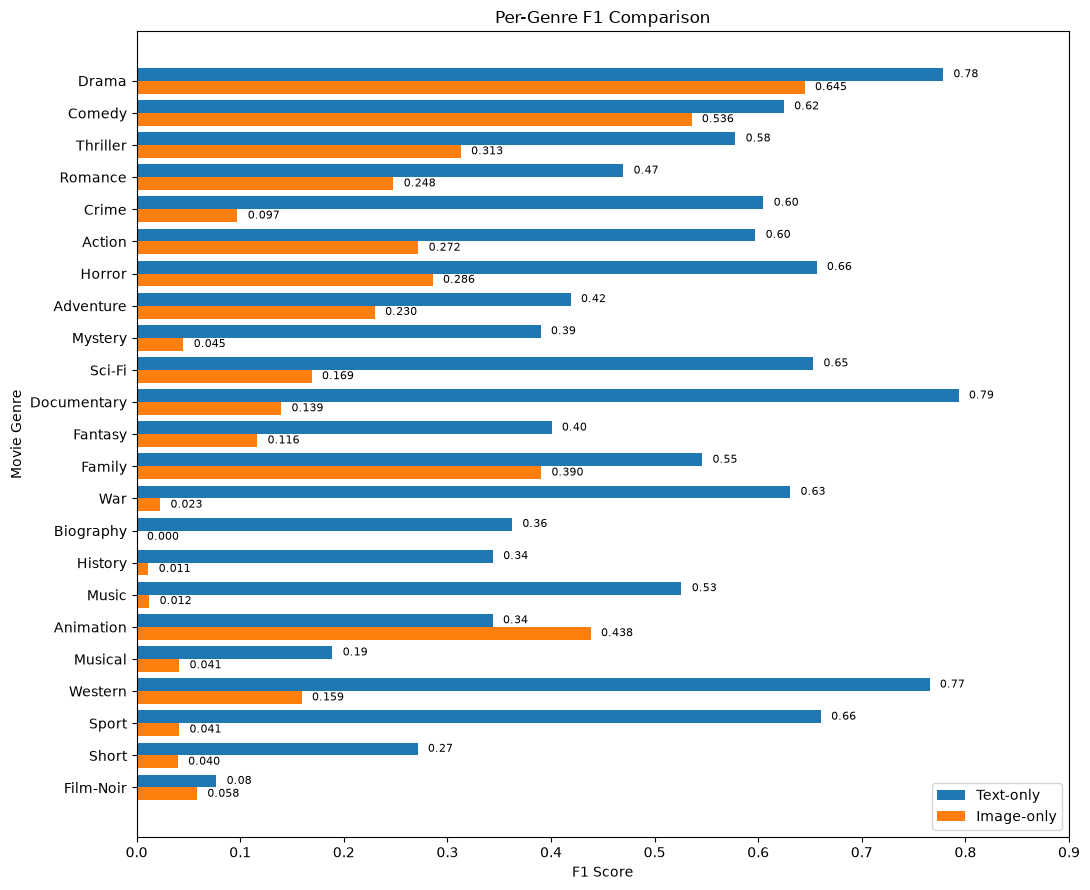

In [263]:
# Sort genres by their frequency in the test set
genre_plot_df = genre_results.sort_values("Support",ascending=False)
y = np.arange(len(genre_plot_df))
plt.figure(figsize=(11, 9))

# Compare F1 scores for both models
text_bars = plt.barh(y-0.2, genre_plot_df["Text F1"],height=0.4, label="Text-only")
image_bars = plt.barh(y+0.2, genre_plot_df["Image F1"],height=0.4, label="Image-only")

# Show the F1 score at the end of each bar
for bar in text_bars:
    plt.text(bar.get_width() + 0.01,
             bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.2f}",
             va="center", fontsize=8)

for bar in image_bars:
    plt.text(bar.get_width() + 0.01,
             bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.3f}",
             va="center", fontsize=8)

# Set labels and title
plt.yticks(y, genre_plot_df["Genre"])
plt.xlabel("F1 Score")
plt.ylabel("Movie Genre")
plt.title("Per-Genre F1 Comparison")
plt.xlim(0, 0.9)
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 11.8.2 Save the per-genre evaluation results

In [266]:
# Save per-genre metrics for the report
genre_results.to_csv("unimodal_per_genre_results.csv", index=False)
print("Per-genre results saved")

Per-genre results saved


**Per-genre evaluation results**

The per-genre results show that the Text-only model performs better than the Image-only model for most genres. For example, Text-only achieves high F1 scores for Documentary (0.793), Drama (0.778) and Western (0.765).

However, both models struggle with some less common genres. Film-Noir has only 98 test samples, with F1 scores of 0.077 for Text-only and 0.058 for Image-only. The Image-only model also has very low recall for Biography, War, History and Music, meaning it misses most positive examples in these categories.

These results suggest that class imbalance may affect model performance, although genre characteristics may also play a role. This helps explain the lower Macro F1 scores, since Macro F1 gives equal importance to all 23 genres regardless of their frequency.

Interestingly, the Image-only model performs better than Text-only for Animation, achieving an F1 of 0.438 compared with 0.344. This suggests that poster images may contain useful visual information for certain genres. I will investigate whether combining text and image features can improve the results through multimodal fusion.

## 12. Early Fusion Model

In this part, I combine the DistilBERT text features and CLIP image features before classification. Following the Project 2.1 proposal, I normalise both modalities separately and project them into 256-dimensional feature spaces. The features are then concatenated and passed through an MLP to predict the 23 movie genres.

I use the same training, validation and test splits as the unimodal models to make the comparison fair.

### 12.1 Prepare the features and labels

In [271]:
# Load the saved text and image features
text_train = np.load("text_train_features.npy")
text_val = np.load("text_val_features.npy")
text_test = np.load("text_test_features.npy")

image_train = np.load("image_train_features.npy")
image_val = np.load("image_val_features.npy")
image_test = np.load("image_test_features.npy")

# Use the genre labels from the same data splits
y_train = labels[train_idx].astype(np.float32)
y_val = labels[val_idx].astype(np.float32)
y_test = labels[test_idx].astype(np.float32)

# Check the feature and label dimensions
print("Training:", text_train.shape, image_train.shape, y_train.shape)
print("Validation:", text_val.shape, image_val.shape, y_val.shape)
print("Test:", text_test.shape, image_test.shape, y_test.shape)

Training: (15581, 768) (15581, 512) (15581, 23)
Validation: (2595, 768) (2595, 512) (2595, 23)
Test: (7783, 768) (7783, 512) (7783, 23)


### 12.2 Create DataLoaders for early fusion

In [274]:
from torch.utils.data import TensorDataset, DataLoader

# Convert features and labels into PyTorch tensors
train_dataset = TensorDataset(torch.tensor(text_train, dtype=torch.float32),
                              torch.tensor(image_train, dtype=torch.float32),
                              torch.tensor(y_train, dtype=torch.float32))

val_dataset = TensorDataset(torch.tensor(text_val, dtype=torch.float32),
                            torch.tensor(image_val, dtype=torch.float32),
                            torch.tensor(y_val, dtype=torch.float32))

test_dataset = TensorDataset(torch.tensor(text_test, dtype=torch.float32),
                             torch.tensor(image_test, dtype=torch.float32),
                             torch.tensor(y_test, dtype=torch.float32))

# Create DataLoaders
train_fusion_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_fusion_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_fusion_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Check one batch
batch_text, batch_image, batch_labels = next(iter(train_fusion_loader))
print("Text batch:", batch_text.shape)
print("Image batch:", batch_image.shape)
print("Labels batch:", batch_labels.shape)


Text batch: torch.Size([64, 768])
Image batch: torch.Size([64, 512])
Labels batch: torch.Size([64, 23])


### 12.3 Define the Early Fusion classifier

In [277]:
import torch.nn as nn
# Define the early fusion classifier
class EarlyFusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Normalise and project text features
        self.text_layer=nn.Sequential(nn.LayerNorm(768),
                                        nn.Linear(768, 256),
                                        nn.ReLU())

        # Normalise and project image features
        self.image_layer = nn.Sequential(nn.LayerNorm(512),
                                         nn.Linear(512, 256),
                                         nn.ReLU())

        # Classify the combined features
        self.classifier = nn.Sequential(nn.Linear(512, 256),
                                        nn.ReLU(),
                                        nn.Dropout(0.3),
                                        nn.Linear(256, 23))

    def forward(self, text_features, image_features):
        text_output = self.text_layer(text_features)
        image_output = self.image_layer(image_features)

        # Combine text and image representations
        combined_features = torch.cat((text_output, image_output), dim=1)
        return self.classifier(combined_features)

# Create the model
early_fusion_model =EarlyFusionModel().to(device)
print(early_fusion_model)

EarlyFusionModel(
  (text_layer): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=768, out_features=256, bias=True)
    (2): ReLU()
  )
  (image_layer): Sequential(
    (0): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=512, out_features=256, bias=True)
    (2): ReLU()
  )
  (classifier): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)


### 12.4 Test the Early Fusion model

In [280]:
# Test the model using one batch
early_fusion_model.eval()
batch_text = batch_text.to(device)
batch_image = batch_image.to(device)
with torch.no_grad():
    sample_outputs = early_fusion_model(batch_text, batch_image)
print("Output shape:", sample_outputs.shape)
print("All outputs finite:", torch.isfinite(sample_outputs).all().item())

# Check the number of trainable parameters
total_parameters = sum(p.numel() for p in early_fusion_model.parameters()
                       if p.requires_grad)
print("Trainable parameters:", total_parameters)

Output shape: torch.Size([64, 23])
All outputs finite: True
Trainable parameters: 467991


The early fusion model combines 256 text features and 256 image features into a 512-dimensional representation. The output shape is (64, 23), matching the 23 genre labels for each movie. All output values are valid.

I use dropout (0.3) to help reduce overfitting. The final layer returns logits, which will be used with BCEWithLogitsLoss during training.

### 12.5 Train and validate the Early Fusion model

I train the early fusion model using the combined text and image features. I use BCEWithLogitsLoss for multi-label classification and evaluate the model on the validation set after each epoch. I also record Micro F1 and Macro F1 to compare the performance with the unimodal baselines.

#### 12.5.1 Set up the training

In [285]:
import time
from sklearn.metrics import f1_score

# Set the random seed
torch.manual_seed(42)

# Training settings
num_epochs = 20
learning_rate = 0.001
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(early_fusion_model.parameters(),lr=learning_rate)

# Store training results
early_history = {"train_loss":[],
                 "val_loss":[],
                 "val_micro_f1":[],
                 "val_macro_f1":[]}
best_val_macro_f1 = -1
best_epoch = 0
print("Epochs:", num_epochs)
print("Learning rate:", learning_rate)
print("Loss function:", type(criterion).__name__)
print("Optimizer:", type(optimizer).__name__)

Epochs: 20
Learning rate: 0.001
Loss function: BCEWithLogitsLoss
Optimizer: Adam


#### 12.5.2 Train the Early Fusion model

In [288]:
# Train and validate the early fusion model
start_time = time.perf_counter()

for epoch in range(num_epochs):

    # Training
    early_fusion_model.train()
    train_loss = 0

    for text_features, image_features, targets in train_fusion_loader:
        text_features = text_features.to(device)
        image_features = image_features.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = early_fusion_model(text_features, image_features)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(targets)
    train_loss /= len(train_fusion_loader.dataset)

    # Validation
    early_fusion_model.eval()
    val_loss = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for text_features, image_features, targets in val_fusion_loader:
            text_features = text_features.to(device)
            image_features = image_features.to(device)
            targets = targets.to(device)

            outputs = early_fusion_model(text_features, image_features)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * len(targets)

            # Convert logits to binary predictions
            probabilities = torch.sigmoid(outputs)
            predictions = (probabilities >= 0.5).int()

            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())
    val_loss /= len(val_fusion_loader.dataset)

    all_predictions = np.concatenate(all_predictions, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Calculate validation F1 scores
    val_micro_f1 = f1_score(all_targets, all_predictions,average="micro", zero_division=0)
    val_macro_f1 = f1_score(all_targets, all_predictions,average="macro", zero_division=0)

    # Save the training history
    early_history["train_loss"].append(train_loss)
    early_history["val_loss"].append(val_loss)
    early_history["val_micro_f1"].append(val_micro_f1)
    early_history["val_macro_f1"].append(val_macro_f1)

    # Save the model with the best validation Macro F1
    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch + 1
        torch.save(early_fusion_model.state_dict(),"best_early_fusion_model.pth")

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Micro F1: {val_micro_f1:.4f} |"
          f"Macro F1: {val_macro_f1:.4f}")
early_training_time = time.perf_counter()-start_time
print("\nBest epoch:", best_epoch)
print("Best validation Macro F1:", round(best_val_macro_f1, 4))
print("Training time (seconds):",round(early_training_time, 2))

Epoch 1/20 | Train Loss: 0.2419 | Val Loss: 0.1982 | Micro F1: 0.5543 |Macro F1: 0.3220
Epoch 2/20 | Train Loss: 0.1924 | Val Loss: 0.1845 | Micro F1: 0.5886 |Macro F1: 0.4190
Epoch 3/20 | Train Loss: 0.1817 | Val Loss: 0.1786 | Micro F1: 0.6095 |Macro F1: 0.4637
Epoch 4/20 | Train Loss: 0.1748 | Val Loss: 0.1785 | Micro F1: 0.6066 |Macro F1: 0.4498
Epoch 5/20 | Train Loss: 0.1682 | Val Loss: 0.1768 | Micro F1: 0.6236 |Macro F1: 0.4914
Epoch 6/20 | Train Loss: 0.1621 | Val Loss: 0.1796 | Micro F1: 0.6235 |Macro F1: 0.5195
Epoch 7/20 | Train Loss: 0.1537 | Val Loss: 0.1806 | Micro F1: 0.6242 |Macro F1: 0.4931
Epoch 8/20 | Train Loss: 0.1472 | Val Loss: 0.1808 | Micro F1: 0.6253 |Macro F1: 0.5163
Epoch 9/20 | Train Loss: 0.1383 | Val Loss: 0.1893 | Micro F1: 0.6206 |Macro F1: 0.5056
Epoch 10/20 | Train Loss: 0.1301 | Val Loss: 0.1896 | Micro F1: 0.6188 |Macro F1: 0.5192
Epoch 11/20 | Train Loss: 0.1214 | Val Loss: 0.2050 | Micro F1: 0.6052 |Macro F1: 0.5088
Epoch 12/20 | Train Loss: 0.11

#### 12.5.3 Load the best Early Fusion model

In [291]:
# Load the model with the best validation Macro F1
early_fusion_model.load_state_dict(
    torch.load("best_early_fusion_model.pth",map_location=device,weights_only=True))

early_fusion_model.eval()
print("Best Early Fusion model loaded.")
print("Selected epoch:", best_epoch)
print("Validation Macro F1:", round(best_val_macro_f1, 4))

Best Early Fusion model loaded.
Selected epoch: 15
Validation Macro F1: 0.5297


In [293]:
# Verify the best epoch using the saved training history
best_epoch_from_history = np.argmax(early_history["val_macro_f1"]) + 1
best_score_from_history = max(early_history["val_macro_f1"])

print("Best epoch from history:", best_epoch_from_history)
print("Best Macro F1 from history:", round(best_score_from_history, 4))
print("Recorded best epoch:", best_epoch)
print("Recorded best Macro F1:", round(best_val_macro_f1, 4))
print("Values match:",best_epoch_from_history == best_epoch 
      and np.isclose(best_score_from_history, best_val_macro_f1))

Best epoch from history: 15
Best Macro F1 from history: 0.5297
Recorded best epoch: 15
Recorded best Macro F1: 0.5297
Values match: True


The Early Fusion model was trained for 20 epochs using the combined DistilBERT and CLIP features. The best validation Macro F1 was **0.5297 at epoch 15** and the corresponding model checkpoint was saved for evaluation.

The training loss continued to decrease, while the validation loss started increasing after the early epochs. This suggests that the model was overfitting. Therefore, I selected the model based on validation Macro F1 rather than using the final epoch.

### 12.6 Visualise training and validation results

#### 12.6.1 Plot training and validation loss

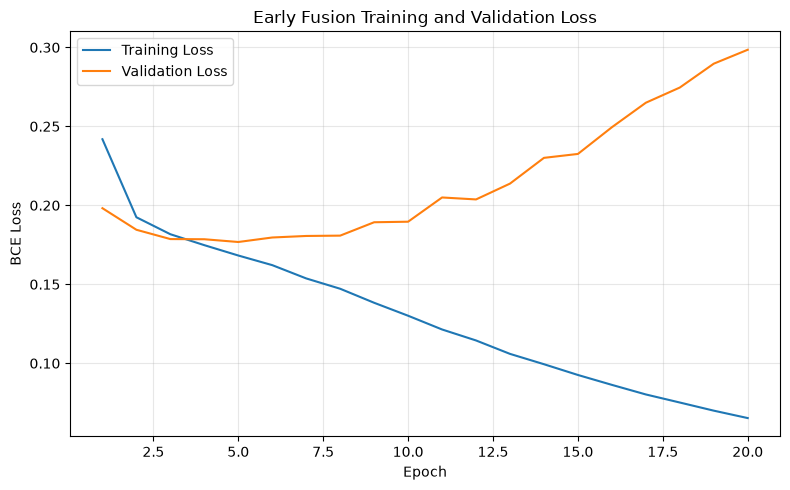

In [297]:
# Plot training and validation loss
epochs = range(1, len(early_history["train_loss"]) + 1)
plt.figure(figsize=(8, 5))

plt.plot(epochs, early_history["train_loss"], label="Training Loss")
plt.plot(epochs, early_history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Early Fusion Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 12.6.2 Plot validation F1 scores

I compare Micro F1 and Macro F1 across epochs to see how the early fusion model performs on the validation set. Macro F1 is also used to select the best model because the dataset has imbalanced genre labels.

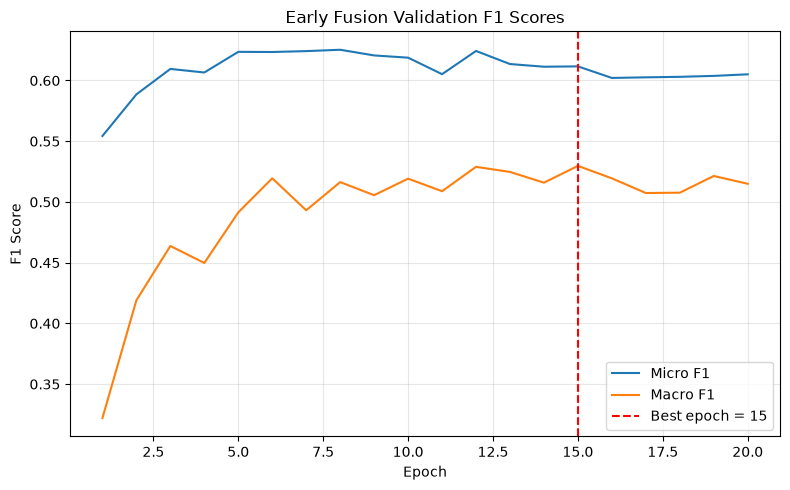

In [300]:
# Plot validation F1 scores
plt.figure(figsize=(8, 5))

plt.plot(epochs, early_history["val_micro_f1"], label="Micro F1")
plt.plot(epochs, early_history["val_macro_f1"], label="Macro F1")

# Mark the best validation Macro F1
plt.axvline(best_epoch, color="red", linestyle="--",
            label=f"Best epoch = {best_epoch}")

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Early Fusion Validation F1 Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 12.6.3 Summarise the best validation results

In [303]:
# Find the best epoch from validation Macro F1
best_index = np.argmax(early_history["val_macro_f1"])
early_val_summary = pd.DataFrame({
    "Metric": ["Best epoch",
               "Validation loss",
               "Validation Micro F1",
               "Validation Macro F1",
               "Training time (s)"],
    "Value":[best_index + 1,
             early_history["val_loss"][best_index],
             early_history["val_micro_f1"][best_index],
             early_history["val_macro_f1"][best_index],
             early_training_time]})
early_val_summary.round(4)

,Metric,Value
0,Best epoch,15.0000
1,Validation loss,0.2325
2,Validation Micro F1,0.6116
3,Validation Macro F1,0.5297
4,Training time (s),20.0997


In [305]:
# Check the training history and selected epoch
print("Recorded epochs:", len(early_history["train_loss"]))
print("Expected epochs:", num_epochs)
print("Best epoch from history:", best_index + 1)
print("Saved best epoch:", best_epoch)
print("Best Macro F1 from history:",round(max(early_history["val_macro_f1"]), 4))
print("Saved best Macro F1:",round(best_val_macro_f1, 4))
print("Epochs match:",len(early_history["train_loss"]) == num_epochs)
print("Best epoch matches:",best_index + 1 == best_epoch)

Recorded epochs: 20
Expected epochs: 20
Best epoch from history: 15
Saved best epoch: 15
Best Macro F1 from history: 0.5297
Saved best Macro F1: 0.5297
Epochs match: True
Best epoch matches: True


In [307]:
# Save the validation summary
early_val_summary.to_csv("early_fusion_validation_results.csv", index=False)
print("Early fusion validation results saved")

Early fusion validation results saved


**Early Fusion training results**

The training loss decreased throughout the 20 epochs, while the validation loss started increasing after the first few epochs. This suggests that the Early Fusion model was overfitting the training data.

The highest validation Macro F1 was **0.5297 at epoch 15**, with a Micro F1 of 0.6116. I selected this checkpoint instead of the final epoch because Macro F1 gives equal importance to all 23 genres, including the less frequent ones. The selected model will be evaluated on the test set in the next section

## 12.7 Evaluate the Early Fusion model on the test set

I evaluate the selected Early Fusion model on the test set using BCE loss, Micro F1 and Macro F1. I use the same test split and prediction threshold of 0.5 as the unimodal baselines to make the comparison consistent.

The model was selected using validation Macro F1, while the test set is used to measure its final performance

#### 12.7.1 Evaluate the selected Early Fusion model

In [312]:
# Evaluate the best Early Fusion model on the test set
early_fusion_model.eval()
criterion = nn.BCEWithLogitsLoss()
test_loss = 0
all_predictions = []
all_targets = []

with torch.no_grad():
    for text_features, image_features, targets in test_fusion_loader:
        text_features = text_features.to(device)
        image_features = image_features.to(device)
        targets = targets.to(device)

        # Get predictions from the Early Fusion model
        outputs = early_fusion_model(text_features, image_features)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * len(targets)

        # Convert model outputs to binary predictions
        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).int()
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

# Calculate the average test loss
early_test_loss = test_loss/len(test_fusion_loader.dataset)

# Combine predictions from all batches
early_predictions = np.concatenate(all_predictions, axis=0)
early_targets = np.concatenate(all_targets, axis=0)

# Calculate the F1 scores
early_micro_f1 = f1_score(early_targets, early_predictions,average="micro", zero_division=0)
early_macro_f1 = f1_score(early_targets, early_predictions,average="macro", zero_division=0)

print("Early Fusion test results:")
print("Test Loss:", round(early_test_loss, 4))
print("Micro F1:", round(early_micro_f1, 4))
print("Macro F1:", round(early_macro_f1, 4))

Early Fusion test results:
Test Loss: 0.2383
Micro F1: 0.6044
Macro F1: 0.5183


#### 12.7.2 Verify the test predictions

In [315]:
# Check the test prediction dimensions
print("Prediction shape:", early_predictions.shape)
print("Target shape:", early_targets.shape)

# Check that predictions are binary
print("Predictions are binary:",np.all((early_predictions == 0) | (early_predictions == 1)))

# Check that the target labels match the test set
print("Test labels match:",np.array_equal(early_targets, y_test))

Prediction shape: (7783, 23)
Target shape: (7783, 23)
Predictions are binary: True
Test labels match: True


#### 12.7.3 Compare Early Fusion with the unimodal baselines

In [318]:
# Compare the Early Fusion model with the unimodal baselines
early_comparison = pd.DataFrame({
    "Model": ["Text-only", "Image-only", "Early Fusion"],
    "Test Loss":[text_test_loss,image_test_loss,early_test_loss],
    "Micro F1":[text_micro_f1,image_micro_f1,early_micro_f1],
    "Macro F1":[text_macro_f1,image_macro_f1,early_macro_f1]})
early_comparison.round(4)

,Model,Test Loss,Micro F1,Macro F1
0,Text-only,0.1801,0.6160,0.5078
1,Image-only,0.2840,0.3830,0.1874
2,Early Fusion,0.2383,0.6044,0.5183


#### 12.7.4 Visualise the model comparison

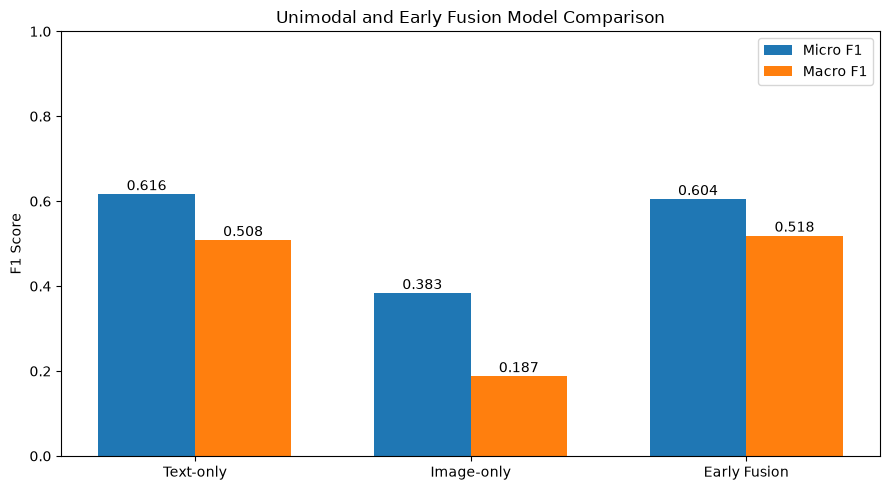

In [321]:
# Compare Micro F1 and Macro F1 across the three models
x = np.arange(len(early_comparison))
width = 0.35
plt.figure(figsize=(9, 5))
micro_bars = plt.bar(x - width / 2,
                     early_comparison["Micro F1"],
                     width,
                     label="Micro F1")
macro_bars = plt.bar(x + width / 2,
                     early_comparison["Macro F1"],
                     width,
                     label="Macro F1")
# Add the F1 values above each bar
for bar in list(micro_bars) + list(macro_bars):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.01,
             f"{bar.get_height():.3f}",
             ha="center")
plt.xticks(x, early_comparison["Model"])
plt.ylabel("F1 Score")
plt.title("Unimodal and Early Fusion Model Comparison")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

#### 12.7.5 Save the Early Fusion test results

In [324]:
# Save the Early Fusion test results
early_test_results = pd.DataFrame({"Metric": ["Test Loss", "Micro F1", "Macro F1"],
                                   "Value": [early_test_loss, early_micro_f1, early_macro_f1]})
early_test_results.to_csv("early_fusion_test_results.csv", index=False)

# Save the comparison table
early_comparison.to_csv("early_fusion_comparison.csv", index=False)
print("Early Fusion test results save")
print("Model comparison saved")

Early Fusion test results save
Model comparison saved


**Early Fusion test results**

The Early Fusion model achieved a Micro F1 of **0.6044** and a Macro F1 of **0.5183** on the test set. It performed much better than the Image-only model. Compared with Text-only, its Micro F1 was slightly lower (0.6044 vs 0.6160), but its Macro F1 was higher (0.5183 vs 0.5078).

The test loss was 0.2383, compared with 0.1801 for Text-only. Together with the increasing validation loss during training, this suggests that the Early Fusion model experienced some overfitting.

Overall, combining text and image features improved Macro F1 slightly but did not improve Micro F1. This suggests that poster information may help with some genres, although text remains the stronger modality overall. I will investigate this further using per-genre evaluation

## 12.8 Evaluate Early Fusion performance for each genre

I evaluate the Early Fusion model across all 23 movie genres using Precision, Recall and F1 scores. I also compare the results with the unimodal baselines to see whether combining text and image features improves performance for individual genres.

#### 12.8.1 Calculate per-genre evaluation metrics

In [329]:
# Calculate Precision, Recall and F1 for each genre
early_precision, early_recall, early_f1, early_support=precision_recall_fscore_support(y_test,
                                                                                         early_predictions,
                                                                                         average=None,
                                                                                         zero_division=0)
# Compare Early Fusion with the unimodal models
early_genre_results = pd.DataFrame({"Genre": genres,
                                    "Support": early_support,
                                    "Text F1": text_f1,
                                    "Image F1": image_f1,
                                    "Early Fusion Precision": early_precision,
                                    "Early Fusion Recall": early_recall,
                                    "Early Fusion F1": early_f1})
early_genre_results.round(3)

,Genre,Support,Text F1,Image F1,Early Fusion Precision,Early Fusion Recall,Early Fusion F1
0,Drama,4187,0.778,0.645,0.740,0.763,0.751
1,Comedy,2586,0.625,0.536,0.677,0.631,0.653
2,Romance,1602,0.470,0.248,0.540,0.438,0.483
3,Thriller,1607,0.578,0.313,0.583,0.566,0.574
4,Crime,1143,0.605,0.097,0.576,0.535,0.555
5,Action,1047,0.597,0.272,0.598,0.589,0.594
6,Adventure,811,0.419,0.230,0.572,0.460,0.510
7,Horror,855,0.656,0.286,0.803,0.477,0.599
8,Documentary,597,0.793,0.139,0.762,0.804,0.782
9,Mystery,647,0.390,0.045,0.498,0.226,0.311


#### 12.8.2 Check whether Early Fusion improves individual genres

In [332]:
# Calculate the F1 difference compared with Text-only
early_genre_results["F1 Difference"] = (
    early_genre_results["Early Fusion F1"] - early_genre_results["Text F1"])
# Find genres where Early Fusion performs better
improved_genres = early_genre_results[early_genre_results["F1 Difference"]> 0]
print("Genres improved by Early Fusion:", len(improved_genres))
print("\nGenres with improved F1:")
display(improved_genres[["Genre", "Support", "Text F1", "Early Fusion F1", "F1 Difference"]].round(3))
# Find the genres with the largest improvements and decreases
print("\nLargest F1 improvements:")
display(early_genre_results.nlargest(5, "F1 Difference")[
        ["Genre", "Text F1", "Early Fusion F1", "F1 Difference"]].round(3))
print("\nLargest F1 decreases:")
display(early_genre_results.nsmallest(5, "F1 Difference")[
        ["Genre", "Text F1", "Early Fusion F1", "F1 Difference"]].round(3))

Genres improved by Early Fusion: 9

Genres with improved F1:


,Genre,Support,Text F1,Early Fusion F1,F1 Difference
1,Comedy,2586,0.625,0.653,0.028
2,Romance,1602,0.470,0.483,0.014
6,Adventure,811,0.419,0.510,0.091
10,Sci-Fi,613,0.653,0.655,0.002
12,Family,517,0.546,0.571,0.025
17,Animation,315,0.344,0.574,0.230
18,Musical,267,0.189,0.320,0.131
21,Short,142,0.271,0.309,0.037
22,Film-Noir,98,0.077,0.186,0.109



Largest F1 improvements:


,Genre,Text F1,Early Fusion F1,F1 Difference
17,Animation,0.344,0.574,0.230
18,Musical,0.189,0.320,0.131
22,Film-Noir,0.077,0.186,0.109
6,Adventure,0.419,0.510,0.091
21,Short,0.271,0.309,0.037



Largest F1 decreases:


,Genre,Text F1,Early Fusion F1,F1 Difference
9,Mystery,0.390,0.311,-0.079
7,Horror,0.656,0.599,-0.058
4,Crime,0.605,0.555,-0.050
14,War,0.631,0.587,-0.044
20,Sport,0.660,0.620,-0.040


#### 12.8.3 Visualise per-genre F1 scores

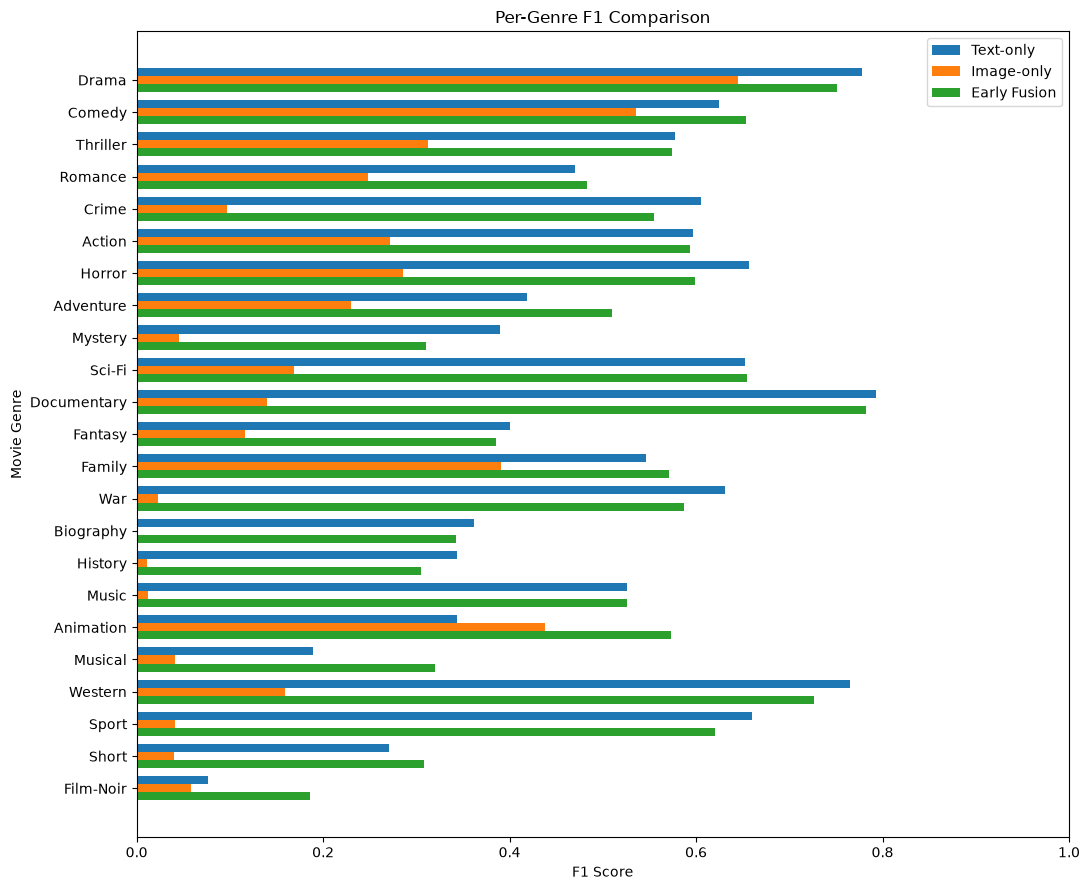

In [335]:
# Sort genres by their frequency in the test set
early_plot_df = early_genre_results.sort_values("Support", ascending=False)
y = np.arange(len(early_plot_df))
plt.figure(figsize=(11, 9))

# Compare F1 scores across the three models
plt.barh(y - 0.25, early_plot_df["Text F1"],height=0.25, label="Text-only")
plt.barh(y, early_plot_df["Image F1"],height=0.25, label="Image-only")
plt.barh(y + 0.25, early_plot_df["Early Fusion F1"],height=0.25, label="Early Fusion")
plt.yticks(y, early_plot_df["Genre"])
plt.xlabel("F1 Score")
plt.ylabel("Movie Genre")
plt.title("Per-Genre F1 Comparison")
plt.xlim(0, 1)
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 12.8.4 Verify and save the per-genre results

In [338]:
# Check that the mean per-genre F1 matches the overall Macro F1
print("Macro F1 from per-genre scores:", round(early_f1.mean(), 4))
print("Macro F1 from test evaluation:", round(early_macro_f1, 4))
print("Scores match:", np.isclose(early_f1.mean(), early_macro_f1))

# Check the number of evaluated genres
print("Number of genres:", len(early_genre_results))

# Save results for the final report
early_genre_results.to_csv("early_fusion_per_genre_results.csv", index=False)
print("Early Fusion per-genre results saved")

Macro F1 from per-genre scores: 0.5183
Macro F1 from test evaluation: 0.5183
Scores match: True
Number of genres: 23
Early Fusion per-genre results saved


**Early Fusion per-genre results**

The Early Fusion model improved F1 scores for **9 out of 23 genres** compared with the Text-only model. The largest improvements were found in Animation (+0.230), Musical (+0.131), Film-Noir (+0.109) and Adventure (+0.091).

However, Early Fusion performed worse for some genres, particularly Mystery (-0.079), Horror (-0.058) and Crime (-0.050). Despite these decreases, its overall Macro F1 (0.5183) was slightly higher than the Text-only model (0.5078).

These results suggest that combining text and image features can help certain genres, especially Animation and Musical but the improvement is not consistent across all genres. Film-Noir also remains difficult to predict despite its improvement, possibly because it has only 98 positive examples in the test set.

I will compare these findings with Late Fusion to see whether combining model predictions produces better results.

## 13. Late Fusion Model
In this part, I combine the predictions from the text-only and image-only models using Late Fusion. Unlike Early Fusion, which combines features before classification, Late Fusion combines the predicted probabilities from two separately trained classifiers

Following Project 2.1 proposal, I first use equal weights for both modalities and then test whether adjusting the weights for each genre improves performance. I use the validation set to select the weights and keep the test set for final evaluation

This allows me to compare Late Fusion with the unimodal baselines and Early Fusion using the same dataset splits and evaluation metrics

### 13.1 Get predicted probabilities from both models

#### 13.1.1 Define a function to get probabilities

In [345]:
# Get predicted probabilities from a trained classifier
def get_probabilities(model, loader):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for features, targets in loader:
            features = features.to(device)

            # Get model outputs and convert them to probabilities
            outputs = model(features)
            batch_probabilities = torch.sigmoid(outputs)
            probabilities.append(batch_probabilities.cpu().numpy())

    return np.concatenate(probabilities, axis=0)

#### 13.1.2 Get validation probabilities

In [348]:
# Get validation probabilities from both models
text_val_probs = get_probabilities(text_classifier, text_val_loader)
image_val_probs = get_probabilities(image_classifier, image_val_loader)

# Check probability dimensions
print("Text validation probabilities:", text_val_probs.shape)
print("Image validation probabilities:", image_val_probs.shape)

# Check that the values are between 0 and 1
print("Text probabilities valid:",np.all((text_val_probs >= 0)&(text_val_probs <= 1)))
print("Image probabilities valid:",np.all((image_val_probs >= 0)&(image_val_probs <= 1)))

# Check that the probabilities match the validation labels
print("Text and labels aligned:",len(text_val_probs) == len(y_val))
print("Image and labels aligned:",len(image_val_probs) == len(y_val))

Text validation probabilities: (2595, 23)
Image validation probabilities: (2595, 23)
Text probabilities valid: True
Image probabilities valid: True
Text and labels aligned: True
Image and labels aligned: True


### 13.2 Apply Equal-Weight Late Fusion

I first combine the probabilities from both classifiers using equal weights of 0.5. This gives the text and image models the same contribution to the final prediction.

I use a threshold of 0.5 to convert the combined probabilities into binary genre predictions, consistent with the previous models.

#### 13.2.1 Combine the predicted probabilities

In [352]:
# Combine text and image probabilities with equal weights
late_val_probs = 0.5 * text_val_probs + 0.5 * image_val_probs

# Convert probabilities into binary predictions
late_val_predictions = (late_val_probs >= 0.5).astype(int)

# Check the combined predictions
print("Combined probabilities shape:", late_val_probs.shape)
print("Predictions shape:", late_val_predictions.shape)
print("All probabilities valid:",np.all((late_val_probs >= 0)&(late_val_probs <= 1)))
print("Predictions are binary:",np.all((late_val_predictions == 0) | (late_val_predictions == 1)))

Combined probabilities shape: (2595, 23)
Predictions shape: (2595, 23)
All probabilities valid: True
Predictions are binary: True


#### 13.2.2 Evaluate Equal-Weight Late Fusion on validation data

In [355]:
# Calculate validation F1 scores
late_val_micro_f1 = f1_score(y_val, late_val_predictions,average="micro", zero_division=0)
late_val_macro_f1 = f1_score(y_val, late_val_predictions,average="macro", zero_division=0)
print("Equal-Weight Late Fusion validation results:")
print("Micro F1:", round(late_val_micro_f1, 4))
print("Macro F1:", round(late_val_macro_f1, 4))

Equal-Weight Late Fusion validation results:
Micro F1: 0.5086
Macro F1: 0.3129


In [357]:
print("Text validation shuffle:",type(text_val_loader.sampler).__name__)
print("Image validation shuffle:",type(image_val_loader.sampler).__name__)

Text validation shuffle: SequentialSampler
Image validation shuffle: SequentialSampler


**Equal-Weight Late Fusion results**

The Equal-Weight Late Fusion model achieved a validation Micro F1 of 0.5086 and Macro F1 of 0.3129. These results suggest that combining both models equally does not necessarily improve classification performance. The weaker image-only model may affect the combined predictions so equal weighting may not be the best choice for this dataset.

In the next step, I will test different weights for each genre using the validation set to see whether giving more importance to the stronger modality improves performance.

### 13.3 Tune Per-Genre Fusion Weights
The Equal-Weight Late Fusion model achieved a validation Micro F1 of 0.5086 and Macro F1 of 0.3129. Since the text-only model performed better than the image-only model, using equal weights may not be the best option.

#### 13.3.1 Test different fusion weights

In [362]:
# Try different text weights for each genre
weights = np.arange(0, 1.01, 0.1)
best_weights = []
best_genre_f1 = []

for j in range(len(genres)):
    best_f1 = -1
    best_weight = 0

    for weight in weights:
        # Combine text and image probabilities
        combined_probs = (weight * text_val_probs[:, j]+(1 - weight)*image_val_probs[:, j])

        # Convert probabilities into binary predictions
        predictions = (combined_probs >= 0.5).astype(int)

        # Calculate F1 for the current genre
        score = f1_score(y_val[:, j], predictions, zero_division=0)

        if score > best_f1:
            best_f1 = score
            best_weight = weight

    best_weights.append(best_weight)
    best_genre_f1.append(best_f1)
best_weights = np.array(best_weights)

# Show the selected weights
weight_results = pd.DataFrame({"Genre": genres,
                               "Text Weight": best_weights,
                               "Image Weight": 1 - best_weights,
                               "Validation F1": best_genre_f1})
weight_results.round(3)

,Genre,Text Weight,Image Weight,Validation F1
0,Drama,0.9,0.1,0.783
1,Comedy,0.6,0.4,0.647
2,Romance,1.0,0.0,0.507
3,Thriller,0.9,0.1,0.579
4,Crime,1.0,0.0,0.619
5,Action,1.0,0.0,0.574
6,Adventure,1.0,0.0,0.462
7,Horror,1.0,0.0,0.680
8,Documentary,0.8,0.2,0.772
9,Mystery,1.0,0.0,0.383


#### 13.3.2 Evaluate the selected weights

I apply the selected weights to the validation probabilities and calculate Micro F1 and Macro F1. I then compare these results with Equal-Weight Late Fusion to check whether tuning the weights improves performance

In [365]:
# Apply the selected weights to all 23 genres
tuned_val_probs = (best_weights * text_val_probs+(1 - best_weights) * image_val_probs)

# Convert probabilities into binary predictions
tuned_val_predictions = (tuned_val_probs >= 0.5).astype(int)

# Calculate validation F1 scores
tuned_val_micro_f1 = f1_score(y_val, 
                              tuned_val_predictions, 
                              average="micro", 
                              zero_division=0)
tuned_val_macro_f1 = f1_score(y_val, 
                              tuned_val_predictions, 
                              average="macro", 
                              zero_division=0)

# Compare equal and tuned weights
late_val_results = pd.DataFrame({"Method": ["Equal Weights", "Per-Genre Weights"],
                                 "Micro F1": [late_val_micro_f1, tuned_val_micro_f1],
                                 "Macro F1": [late_val_macro_f1, tuned_val_macro_f1]})
late_val_results.round(4)

,Method,Micro F1,Macro F1
0,Equal Weights,0.5086,0.3129
1,Per-Genre Weights,0.6308,0.5240


**Per-Genre Weight Tuning Results**

The tuned per-genre weights improved validation Micro F1 from 0.5086 to 0.6308 and Macro F1 from 0.3129 to 0.5240 compared with Equal-Weight Late Fusion.

Most genres selected higher weights for text, which is consistent with the stronger performance of the text-only model. However, Animation selected an image weight of 1.0, suggesting that image prediction were more useful for this genre on the validation set.

These results suggest that different genres may require different contributions from text and images. However, the weights were selected using the validation set, so their performance needs to be checked on the test set to assess generalisation

In [372]:
# Save the selected weights and validation results
weight_results.to_csv("late_fusion_weights.csv", index=False)
late_val_results.to_csv("late_fusion_validation_results.csv", index=False)
np.save("late_fusion_best_weights.npy", best_weights)
print("Late Fusion weights and validation results saved")

Late Fusion weights and validation results saved


### 13.4 Evaluate Late Fusion on the Test Set

I evaluate both Equal-Weight and Tuned Per-Genre Late Fusion on the test set. The weights were selected using the validation set and I keep them unchanged during testing.

I use the same prediction threshold of 0.5 and calculate Micro F1 and Macro F1 to compare the two Late Fusion approaches with the previous models

#### 13.4.1 Get test probabilities from both models

In [378]:
# Get test probabilities from both unimodal models
text_test_probs = get_probabilities(text_classifier, text_test_loader)
image_test_probs = get_probabilities(image_classifier, image_test_loader)

# Check the probability dimensions
print("Text test probabilities:", text_test_probs.shape)
print("Image test probabilities:", image_test_probs.shape)

# Check that the probabilities are valid
print("Text probabilities valid:",np.all((text_test_probs >= 0)&(text_test_probs <= 1)))
print("Image probabilities valid:",np.all((image_test_probs >= 0)&(image_test_probs <= 1)))

# Check alignment with test labels
print("Text and labels aligned:", len(text_test_probs) == len(y_test))
print("Image and labels aligned:", len(image_test_probs) == len(y_test))

Text test probabilities: (7783, 23)
Image test probabilities: (7783, 23)
Text probabilities valid: True
Image probabilities valid: True
Text and labels aligned: True
Image and labels aligned: True


#### 13.4.2 Apply Equal-Weight Late Fusion

I combine the test probabilities using equal weights of 0.5 for text and images, following the same method used on the validation set

In [380]:
# Combine test probabilities using equal weights
late_test_probs = 0.5 * text_test_probs + 0.5 * image_test_probs

# Convert probabilities into binary predictions
late_test_predictions = (late_test_probs >= 0.5).astype(int)

# Calculate test F1 scores
late_test_micro_f1 = f1_score(y_test, late_test_predictions,average="micro", zero_division=0)
late_test_macro_f1 = f1_score(y_test, late_test_predictions,average="macro", zero_division=0)

print("Equal-Weight Late Fusion test results:")
print("Micro F1:", round(late_test_micro_f1, 4))
print("Macro F1:", round(late_test_macro_f1, 4))

Equal-Weight Late Fusion test results:
Micro F1: 0.5122
Macro F1: 0.3105


#### 13.4.3 Apply Tuned Per-Genre Weights

I apply the 23 weights selected from the validation set to the test probabilities. The same weights are used without further tuning so that the test set remains independent of model selection.

In [382]:
# Apply the selected weights to the test probabilities
tuned_test_probs = (best_weights * text_test_probs+(1 - best_weights) * image_test_probs)

# Convert probabilities into binary predictions
tuned_test_predictions = (tuned_test_probs >= 0.5).astype(int)

# Calculate test F1 scores
tuned_test_micro_f1 = f1_score(y_test, tuned_test_predictions,average="micro", zero_division=0)
tuned_test_macro_f1 = f1_score(y_test, tuned_test_predictions,average="macro", zero_division=0)
print("Tuned Per-Genre Late Fusion test results:")
print("Micro F1:", round(tuned_test_micro_f1, 4))
print("Macro F1:", round(tuned_test_macro_f1, 4))

Tuned Per-Genre Late Fusion test results:
Micro F1: 0.6186
Macro F1: 0.5105


#### 13.4.4 Compare the Late Fusion Results

I compare the test results of Equal-Weight and Tuned Per-Genre Late Fusion. This helps check whether selecting different weights for each genre improves performance on unseen data.

In [384]:
# Compare the two Late Fusion methods
late_test_results = pd.DataFrame({"Method": ["Equal Weights", "Per-Genre Weights"],
                                  "Micro F1": [late_test_micro_f1, tuned_test_micro_f1],
                                  "Macro F1": [late_test_macro_f1, tuned_test_macro_f1]})

late_test_results.round(4)

,Method,Micro F1,Macro F1
0,Equal Weights,0.5122,0.3105
1,Per-Genre Weights,0.6186,0.5105


In [386]:
# Save the Late Fusion test results
late_test_results.to_csv("late_fusion_test_results.csv", index=False)
print("Late Fusion test results saved")

Late Fusion test results saved


**Late Fusion test results**

The Tuned Per-Genre Late Fusion model performed better than Equal-Weight Late Fusion on the test set. Micro F1 increased from 0.5122 to 0.6186, while Macro F1 increased from 0.3105 to 0.5105.

Compared with the Text-only baseline, the tuned model achieved slightly higher Micro F1 (0.6186 vs 0.6160) and Macro F1 (0.5105 vs 0.5078). These results suggest that adjusting the fusion weights for individual genres is more effective than giving both modalities equal importance. However, the improvement over the Text-only model is small so the contribution of image features needs further evaluation.


## 13.5 Compare All Models

I compare the test results of the two unimodal baselines, Early Fusion and both Late Fusion methods. All models use the same test set of 7783 movies and the same prediction threshold of 0.5.

I use Micro F1 and Macro F1 to compare their overall performance and check whether combining text and image information improves genre classification.


#### 13.5.1 Create the final model comparison table

In [390]:
# Compare the test results of all five models
final_results = pd.DataFrame({
    "Model": ["Text-only", "Image-only", "Early Fusion","Equal-Weight Late Fusion", "Tuned Late Fusion"],
    "Micro F1":[text_micro_f1, image_micro_f1, early_micro_f1,late_test_micro_f1, tuned_test_micro_f1],
    "Macro F1":[text_macro_f1, image_macro_f1, early_macro_f1,late_test_macro_f1, tuned_test_macro_f1]})
# Display the comparison table
final_results.round(4)

,Model,Micro F1,Macro F1
0,Text-only,0.6160,0.5078
1,Image-only,0.3830,0.1874
2,Early Fusion,0.6044,0.5183
3,Equal-Weight Late Fusion,0.5122,0.3105
4,Tuned Late Fusion,0.6186,0.5105


#### 13.5.2 Visualise the model comparison

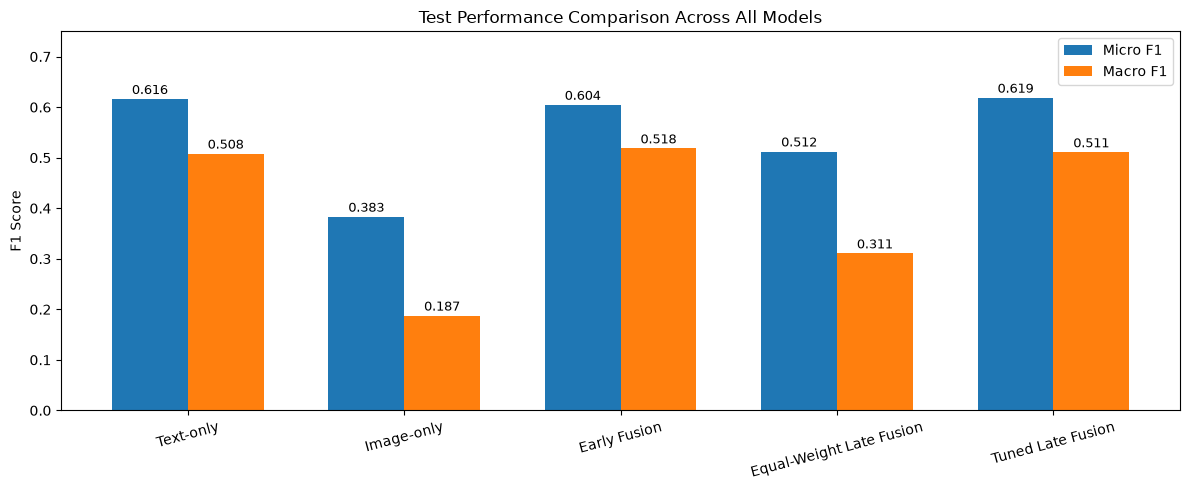

In [393]:
# Plot Micro F1 and Macro F1 for all models
x = np.arange(len(final_results))
width = 0.35
plt.figure(figsize=(12, 5))
micro_bars = plt.bar(x - width / 2,
                     final_results["Micro F1"],
                     width,
                     label="Micro F1")

macro_bars = plt.bar(x + width / 2,
                     final_results["Macro F1"],
                     width,
                     label="Macro F1")

# Show F1 values above the bars
for bar in list(micro_bars) + list(macro_bars):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.01,
             f"{bar.get_height():.3f}",
             ha="center",
             fontsize=9)

plt.xticks(x, final_results["Model"], rotation=15)
plt.ylabel("F1 Score")
plt.title("Test Performance Comparison Across All Models")
plt.ylim(0, 0.75)
plt.legend()
plt.tight_layout()
plt.show()

#### 13.5.3 Compare improvements over the text-only baseline

In [396]:
# Compare fusion models against the text-only baseline
fusion_improvements = final_results.iloc[2:].copy()
fusion_improvements["Micro F1 Difference"] = (fusion_improvements["Micro F1"] - text_micro_f1)
fusion_improvements["Macro F1 Difference"] = (fusion_improvements["Macro F1"] - text_macro_f1)

# Display the F1 differences
fusion_improvements[["Model", "Micro F1 Difference", "Macro F1 Difference"]].round(4)

,Model,Micro F1 Difference,Macro F1 Difference
2,Early Fusion,-0.0115,0.0104
3,Equal-Weight Late Fusion,-0.1038,-0.1973
4,Tuned Late Fusion,0.0026,0.0027


#### 13.5.4 Save the final comparison results

In [399]:
# Save the final model comparison
final_results.to_csv("final_model_comparison.csv", index=False)

# Save the comparison with the text-only baseline
fusion_improvements.to_csv("fusion_improvements.csv", index=False)
print("Final model comparison saved.")
print("Fusion improvements saved.")

Final model comparison saved.
Fusion improvements saved.


#### 13.5.5 Interpret the results

**Model comparison results**

The results show that the Text-only model performs much better than the Image-only model, suggesting that plot summaries provide more useful information for movie genre classification in this dataset.

Early Fusion achieved a Micro F1 of 0.6044 and Macro F1 of 0.5183. Although its Micro F1 was lower than Text-only (0.6160), it achieved the highest Macro F1 among all five models. This suggests that combining text and image features can improve performance across genres, even when overall Micro F1 decreases.

Equal-Weight Late Fusion performed worse than the other approaches, with a Micro F1 of 0.5122 and Macro F1 of 0.3105. However, Tuned Late Fusion achieved the highest Micro F1 of 0.6186 and a Macro F1 of 0.5105, slightly higher than the Text-only baseline.

These results show a trade-off between the fusion methods. Tuned Late Fusion performed best under Micro F1, while Early Fusion achieved the highest Macro F1. Overall, text remains the stronger modality, but image features can provide useful additional information. The improvements over Text-only are relatively small, so further evaluation is needed to understand how consistently fusion improves classification.

### 13.6 Evaluate Late Fusion Performance for Each Genre

I evaluate the Tuned Late Fusion model across all 23 movie genres using Precision, Recall and F1 scores. I compare the results with the Text-only and Early Fusion models to see which genres benefit from combining the two modalities.

I use the same test set and prediction threshold of 0.5 as in the previous evaluations

#### 13.6.1 Calculate per-genre evaluation metrics

In [407]:
# Calculate Precision, Recall and F1 for each genre
late_precision,late_recall,late_f1,late_support=precision_recall_fscore_support(y_test,
                                                                                tuned_test_predictions,
                                                                                average=None,
                                                                                zero_division=0)
# Compare Late Fusion with the previous models
late_genre_results = pd.DataFrame({"Genre": genres,
                                   "Support": late_support,
                                   "Text F1": text_f1,
                                   "Image F1": image_f1,
                                   "Early Fusion F1": early_f1,
                                   "Late Fusion Precision": late_precision,
                                   "Late Fusion Recall": late_recall,
                                   "Late Fusion F1": late_f1})

late_genre_results.round(3)

,Genre,Support,Text F1,Image F1,Early Fusion F1,Late Fusion Precision,Late Fusion Recall,Late Fusion F1
0,Drama,4187,0.778,0.645,0.751,0.728,0.843,0.781
1,Comedy,2586,0.625,0.536,0.653,0.803,0.530,0.638
2,Romance,1602,0.470,0.248,0.483,0.635,0.373,0.470
3,Thriller,1607,0.578,0.313,0.574,0.668,0.504,0.574
4,Crime,1143,0.605,0.097,0.555,0.665,0.555,0.605
5,Action,1047,0.597,0.272,0.594,0.717,0.512,0.597
6,Adventure,811,0.419,0.230,0.510,0.724,0.295,0.419
7,Horror,855,0.656,0.286,0.599,0.735,0.593,0.656
8,Documentary,597,0.793,0.139,0.782,0.835,0.727,0.777
9,Mystery,647,0.390,0.045,0.311,0.557,0.300,0.390


#### 13.6.2 Verify the per-genre results

In [410]:
# Check that the mean per-genre F1 matches the overall Macro F1
print("Macro F1 from per-genre scores:", round(late_f1.mean(), 4))
print("Macro F1 from test evaluation:", round(tuned_test_macro_f1, 4))
print("Scores match:", np.isclose(late_f1.mean(), tuned_test_macro_f1))

# Check the number of genres and test samples
print("Number of genres:", len(late_genre_results))
print("Prediction shape:", tuned_test_predictions.shape)
print("Test label shape:", y_test.shape)

Macro F1 from per-genre scores: 0.5105
Macro F1 from test evaluation: 0.5105
Scores match: True
Number of genres: 23
Prediction shape: (7783, 23)
Test label shape: (7783, 23)



#### 13.6.3 Compare Per-Genre F1 Improvements

I compare the F1 scores of Tuned Late Fusion with the Text-only and Early Fusion models. This helps identify which genres improve after combining predictions and which genres perform better with Early Fusion

In [413]:

# Calculate F1 differences compared with Text-only and Early Fusion
late_genre_results["Difference vs Text"] = (
    late_genre_results["Late Fusion F1"] - late_genre_results["Text F1"])

late_genre_results["Difference vs Early"] = (
    late_genre_results["Late Fusion F1"] - late_genre_results["Early Fusion F1"])

# Count how many genres improve
improved_vs_text = (late_genre_results["Difference vs Text"] > 0).sum()
improved_vs_early = (late_genre_results["Difference vs Early"] > 0).sum()

print("Genres improved compared with Text-only:", improved_vs_text)
print("Genres improved compared with Early Fusion:", improved_vs_early)

# Show genres where Late Fusion improves over Text-only
print("\nGenres improved compared with Text-only:")
display(
    late_genre_results[
        late_genre_results["Difference vs Text"] > 0][["Genre", "Support", "Text F1", "Late Fusion F1",
                                                       "Difference vs Text"]].round(3))

# Show the largest improvements compared with Early Fusion
print("\nLargest improvements compared with Early Fusion:")
display(
    late_genre_results.nlargest(5, "Difference vs Early")[["Genre", "Early Fusion F1", "Late Fusion F1",
                                                           "Difference vs Early"]].round(3))

# Show the largest decreases compared with Early Fusion
print("\nLargest decreases compared with Early Fusion:")
display(
    late_genre_results.nsmallest(5, "Difference vs Early")[["Genre", "Early Fusion F1", "Late Fusion F1",
                                                            "Difference vs Early"]].round(3))

Genres improved compared with Text-only: 4
Genres improved compared with Early Fusion: 13

Genres improved compared with Text-only:


,Genre,Support,Text F1,Late Fusion F1,Difference vs Text
0,Drama,4187,0.778,0.781,0.003
1,Comedy,2586,0.625,0.638,0.014
12,Family,517,0.546,0.551,0.005
17,Animation,315,0.344,0.438,0.095



Largest improvements compared with Early Fusion:


,Genre,Early Fusion F1,Late Fusion F1,Difference vs Early
9,Mystery,0.311,0.390,0.079
7,Horror,0.599,0.656,0.058
4,Crime,0.555,0.605,0.050
14,War,0.587,0.631,0.044
20,Sport,0.620,0.660,0.040



Largest decreases compared with Early Fusion:


,Genre,Early Fusion F1,Late Fusion F1,Difference vs Early
17,Animation,0.574,0.438,-0.135
18,Musical,0.320,0.189,-0.131
22,Film-Noir,0.186,0.077,-0.109
6,Adventure,0.510,0.419,-0.091
21,Short,0.309,0.246,-0.063


**Per-Genre F1 Comparison**

Tuned Late Fusion improved F1 scores for 4 out of 23 genres compared with Text-only: Drama (+0.003), Comedy (+0.014), Family (+0.005) and Animation (+0.095).

Compared with Early Fusion, Tuned Late Fusion achieved higher F1 scores for 13 genres, with the largest improvements in Mystery (+0.079), Horror (+0.058) and Crime (+0.050). However, Early Fusion performed better for several genres, particularly Animation, Musical, Film-Noir and Adventure. These results show that different fusion methods perform better for different genres. Tuned Late Fusion generally relies more on text predictions, while Early Fusion can be more effective for some genres

#### 13.6.4 Visualise per-genre F1 scores

I visualise the per-genre F1 scores of Text-only, Early Fusion and Tuned Late Fusion. The genres are sorted by their frequency in the test set to make the results easier to compare. This helps show which genres benefit from Early Fusion or Late Fusion and where the Text-only model still performs better

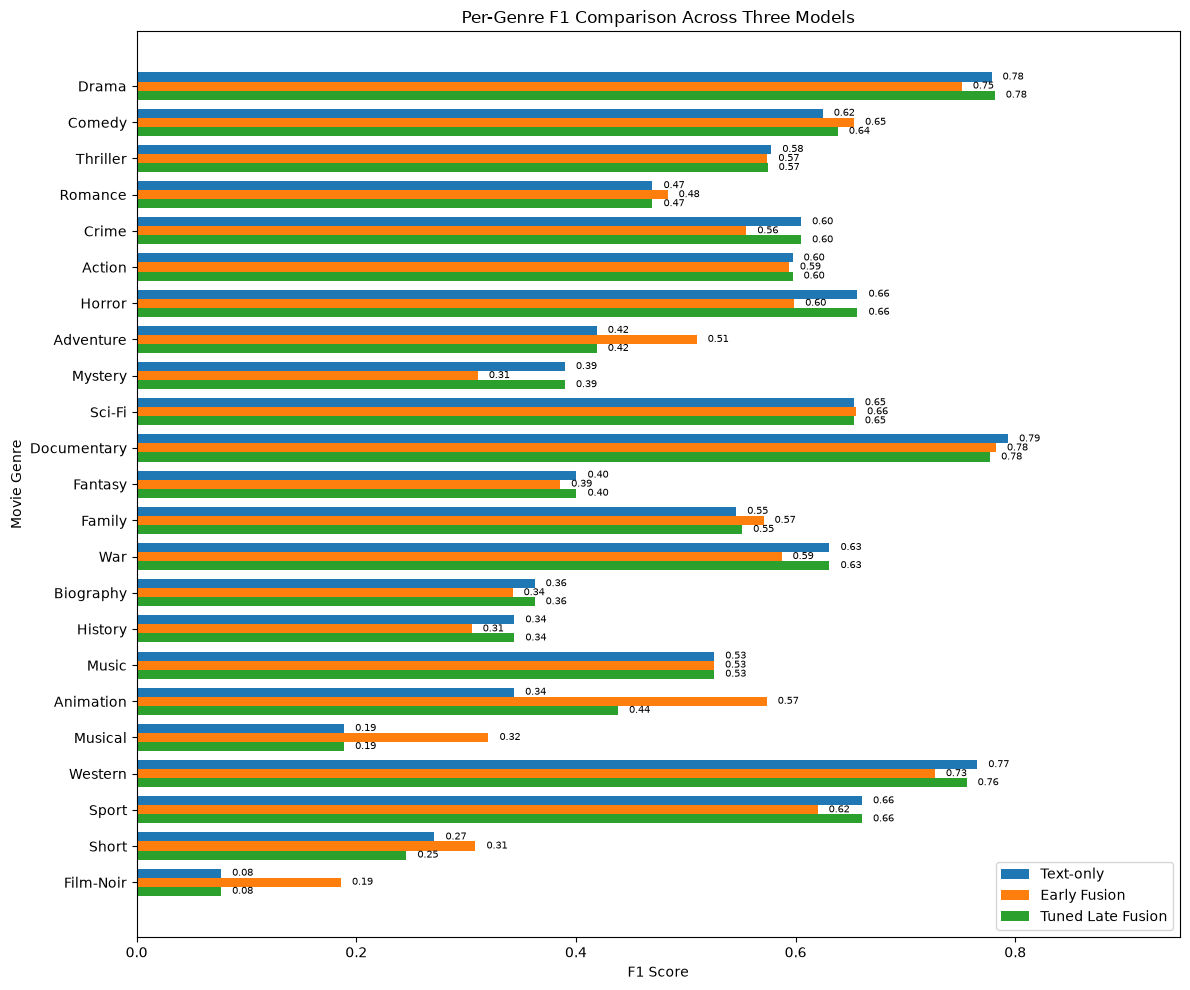

In [417]:
# Sort genres by their frequency in the test set
late_plot_df = late_genre_results.sort_values("Support", ascending=False)
y = np.arange(len(late_plot_df))
plt.figure(figsize=(12, 10))

# Compare F1 scores across the three models
text_bars = plt.barh(y-0.25, late_plot_df["Text F1"],height=0.25, label="Text-only")
early_bars = plt.barh(y, late_plot_df["Early Fusion F1"],height=0.25, label="Early Fusion")
late_bars = plt.barh(y+0.25, late_plot_df["Late Fusion F1"],height=0.25,label="Tuned Late Fusion")

# Add F1 values at the end of each bar
for bar in list(text_bars) + list(early_bars) + list(late_bars):
    plt.text(bar.get_width() + 0.01,
             bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.2f}",
             va="center", fontsize=7)

# Set labels and title
plt.yticks(y, late_plot_df["Genre"])
plt.xlabel("F1 Score")
plt.ylabel("Movie Genre")
plt.title("Per-Genre F1 Comparison Across Three Models")
plt.xlim(0, 0.95)
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Per-Genre F1 Visualisation**

The chart shows that Tuned Late Fusion performs similarly to Text-only for most genres, with small improvements in Drama (0.778 to 0.781), Comedy (0.625 to 0.638) and Family (0.546 to 0.551). Animation shows a larger improvement from Text-only (0.344) to Tuned Late Fusion (0.438). However, Early Fusion achieves an even higher F1 of 0.574 for this genre.

Early Fusion also performs better than Text-only for some other genres, including Musical (0.189 to 0.320), Film-Noir (0.077 to 0.186) and Adventure (0.419 to 0.510). These results suggest that Early Fusion can benefit certain genres, while Tuned Late Fusion relies more heavily on text prediction. Combining both modalities does not consistently improve performance for every genre

#### 13.6.5 Save and interpret the per-genre results

I save the per-genre evaluation results for the final report. I also check how many genres improve compared with the Text-only and Early Fusion models.

In [421]:
# Save the per-genre results
late_genre_results.to_csv("late_fusion_per_genre_results.csv", index=False)
print("Late Fusion per-genre results saved.")

# Summarise the number of improved genres
print("\nSummary of per-genre improvements:")
print("Total genres:", len(late_genre_results))
print("Improved over Text-only:", improved_vs_text)
print("Improved over Early Fusion:", improved_vs_early)

# Check the overall Macro F1
print("\nOverall Macro F1 scores:")
print("Text-only:", round(text_f1.mean(), 4))
print("Early Fusion:", round(early_f1.mean(), 4))
print("Tuned Late Fusion:", round(late_f1.mean(), 4))

# Check that the file was saved correctly
saved_results = pd.read_csv("late_fusion_per_genre_results.csv")
print("\nSaved file shape:", saved_results.shape)
print("File saved correctly:", saved_results.shape == late_genre_results.shape)

Late Fusion per-genre results saved.

Summary of per-genre improvements:
Total genres: 23
Improved over Text-only: 4
Improved over Early Fusion: 13

Overall Macro F1 scores:
Text-only: 0.5078
Early Fusion: 0.5183
Tuned Late Fusion: 0.5105

Saved file shape: (23, 10)
File saved correctly: True


**Late Fusion per-genre results**

Tuned Late Fusion improved F1 scores for 4 out of 23 genres compared with Text-only, including Drama, Comedy, Family and Animation. Compared with Early Fusion, it achieved higher F1 scores for 13 genres.

However, its overall Macro F1 (0.5105) was lower than Early Fusion (0.5183), although it was slightly higher than Text-only (0.5078). Early Fusion was more effective for some individual genres, particularly Animation, Musical, Film-Noir and Adventure.

These results show that the best fusion method can depend on the genre. Text-only remains a strong baseline, while Early Fusion and Tuned Late Fusion provide different benefits. Overall, combining both modalities gives limited but useful improvements in this experiment.

## 14. Further Evaluation and Error Analysis

In this part, I examine the prediction errors of the Text-only, Early Fusion and Tuned Late Fusion models. I compare their incorrect predictions to understand the limitations of each approach.

I use the same test set of 7783 movies and focus on false positives and false negatives across the 23 genres.


### 14.1 Analyse false positives and false negatives

I compare the number of correct positive predictions, false positives and false negatives for each model. This helps identify whether a model tends to predict too many genres or miss genres that are actually present.


In [429]:

# Calculate prediction errors for each model
models_predictions = {"Text-only": text_predictions,
                      "Early Fusion": early_predictions,
                      "Tuned Late Fusion": tuned_test_predictions}
error_results =[]

for model_name, predictions in models_predictions.items():
    # Count true positives, false positives and false negatives
    tp = np.sum((y_test == 1) & (predictions == 1))
    fp = np.sum((y_test == 0) & (predictions == 1))
    fn = np.sum((y_test == 1) & (predictions == 0))

    error_results.append({"Model": model_name,
                          "True Positives": tp,
                          "False Positives": fp,
                          "False Negatives": fn})

# Compare the error counts
error_df = pd.DataFrame(error_results)
error_df

,Model,True Positives,False Positives,False Negatives
0,Text-only,10528,4176,8952
1,Early Fusion,10877,5633,8603
2,Tuned Late Fusion,10486,3939,8994


In [431]:
#Check that all models use the same test labels
total_positive_labels = np.sum(y_test)
print("Total positive genre labels:", total_positive_labels)

for model_name, predictions in models_predictions.items():
    print(model_name, "shape:", predictions.shape)
    print("TP + FN:", np.sum((y_test == 1)&(predictions == 1))+np.sum((y_test == 1)&(predictions == 0)))

Total positive genre labels: 19480.0
Text-only shape: (7783, 23)
TP + FN: 19480
Early Fusion shape: (7783, 23)
TP + FN: 19480
Tuned Late Fusion shape: (7783, 23)
TP + FN: 19480


**Prediction error analysis**

The results show that Early Fusion has the highest number of true positives (10877), but it also produces the most false positives (5633). This suggests that the model predicts more genre labels, including many incorrect ones.

Tuned Late Fusion has the fewest false positives (3939), although it misses slightly more positive labels than the other models. This helps explain why it achieves the highest Micro F1 score of 0.6186.

Overall, the results show that combining modalities doesn't always reduce prediction errors. Different fusion methods have different trade-offs between false positives and false negatives.

## 14.2 Visualise prediction errors

I visualise the false positives and false negatives of the three models to compare their prediction errors. This makes it easier to see whether each model produces more incorrect genre predictions or misses more actual genres.

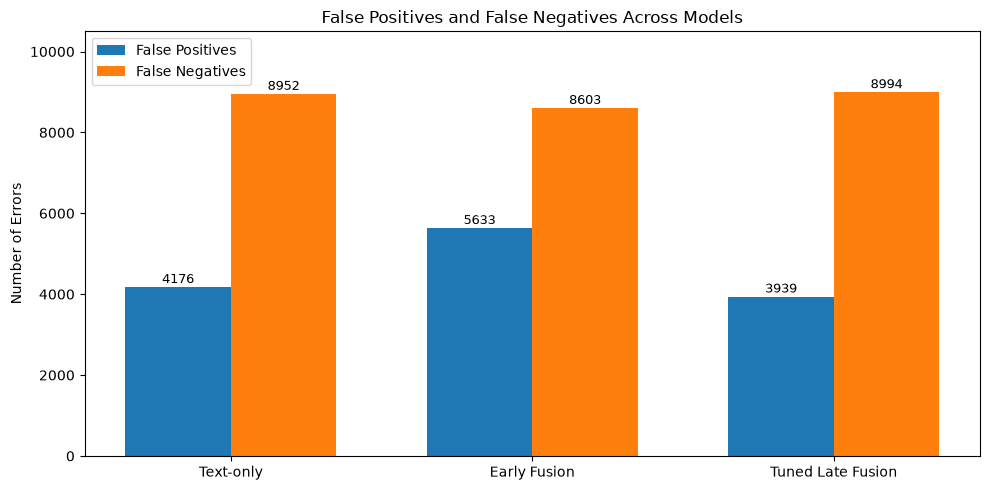

In [435]:
# Compare false positives and false negatives across the three models
x = np.arange(len(error_df))
width = 0.35
plt.figure(figsize=(10, 5))

fp_bars = plt.bar(x - width / 2,
                  error_df["False Positives"],
                  width,
                  label="False Positives")

fn_bars = plt.bar(x + width / 2,
                  error_df["False Negatives"],
                  width,
                  label="False Negatives")

# Show error counts above the bars
for bar in list(fp_bars) + list(fn_bars):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 100,
             f"{int(bar.get_height())}",
             ha="center",
             fontsize=9)

plt.xticks(x, error_df["Model"])
plt.ylabel("Number of Errors")
plt.title("False Positives and False Negatives Across Models")
plt.ylim(0, 10500)
plt.legend()
plt.tight_layout()
plt.show()

**Error comparison**

The chart shows that Early Fusion produces the most false positives (5633), while Tuned Late Fusion has the fewest (3939). The number of false negatives is relatively similar across the three models. Early Fusion has the fewest false negatives (8,603), but this comes with a much higher number of false positives.

This helps explain why Tuned Late Fusion achieves the highest Micro F1 score (0.6186), even though Early Fusion correctly identifies more positive genre labels.

### 14.3 Analyse individual prediction examples

I examine individual movies from the test set to understand where the models make different predictions. I compare the actual genres with the predictions from Text-only, Early Fusion and Tuned Late Fusion.

I focus on examples where Early Fusion corrects errors made by Text-only, as well as cases where it introduces additional errors.

#### 14.3.1 Identify examples where Early Fusion helps or performs worse

In [440]:
# Count incorrect genre predictions for each movie
text_errors = np.sum(text_predictions != y_test, axis=1)
early_errors = np.sum(early_predictions != y_test, axis=1)
late_errors = np.sum(tuned_test_predictions != y_test, axis=1)

# Find movies where Early Fusion performs better or worse than Text-only
early_better = np.where(early_errors < text_errors)[0]
early_worse = np.where(early_errors > text_errors)[0]
same_errors = np.where(early_errors == text_errors)[0]

print("Movies where Early Fusion has fewer errors:", len(early_better))
print("Movies where Early Fusion has more errors:", len(early_worse))
print("Movies with the same number of errors:", len(same_errors))

# Check the total number of test movies
print("Total test movies:", len(text_errors))
print("All movies accounted for:",len(early_better) + len(early_worse) + len(same_errors) == len(y_test))

Movies where Early Fusion has fewer errors: 1899
Movies where Early Fusion has more errors: 2532
Movies with the same number of errors: 3352
Total test movies: 7783
All movies accounted for: True


#### 14.3.2 Display individual prediction examples
I display the actual and predicted genres for selected movies. This makes it easier to identify which genres are missed or incorrectly added by each model.

In [443]:
# Convert a binary label vector into genre names
def get_genre_names(label_vector):
    return [genres[j] for j in range(len(genres)) if label_vector[j] == 1]

# Display predictions for one test movie
def show_movie_predictions(index):
    print("Test movie index:", index)
    print("Movie ID:", movie_ids[test_idx[index]])

    print("\nActual genres:")
    print(get_genre_names(y_test[index]))

    print("\nText-only predictions:")
    print(get_genre_names(text_predictions[index]))

    print("\nEarly Fusion predictions:")
    print(get_genre_names(early_predictions[index]))

    print("\nTuned Late Fusion predictions:")
    print(get_genre_names(tuned_test_predictions[index]))

    print("\nIncorrect labels:")
    print("Text-only:", text_errors[index])
    print("Early Fusion:", early_errors[index])
    print("Tuned Late Fusion:", late_errors[index])

#### 14.3.3 Examine examples where Early Fusion improves predictions

In [451]:
# Show three examples where Early Fusion has fewer errors
for index in early_better[:3]:
    show_movie_predictions(index)
    print("-" * 50)

Test movie index: 11
Movie ID: 21282

Actual genres:
['Drama', 'Thriller', 'Crime', 'Adventure', 'Mystery']

Text-only predictions:
['Action', 'Adventure']

Early Fusion predictions:
['Drama', 'Action', 'Adventure']

Tuned Late Fusion predictions:
['Action', 'Adventure']

Incorrect labels:
Text-only: 5
Early Fusion: 4
Tuned Late Fusion: 5
--------------------------------------------------
Test movie index: 13
Movie ID: 4265

Actual genres:
['Drama', 'Family']

Text-only predictions:
['Drama']

Early Fusion predictions:
['Drama', 'Family']

Tuned Late Fusion predictions:
['Drama', 'Animation']

Incorrect labels:
Text-only: 1
Early Fusion: 0
Tuned Late Fusion: 2
--------------------------------------------------
Test movie index: 14
Movie ID: 1998

Actual genres:
['Comedy', 'Family', 'Animation']

Text-only predictions:
['Drama']

Early Fusion predictions:
['Drama', 'Comedy', 'Adventure', 'Fantasy', 'Family', 'Animation']

Tuned Late Fusion predictions:
['Drama', 'Comedy', 'Family', 'Ani

#### 14.3.4 Examine examples where Early Fusion performs worse

In [449]:
# Show three examples where Early Fusion has more errors
for index in early_worse[:3]:
    show_movie_predictions(index)
    print("-" * 50)

Test movie index: 2
Movie ID: 9300

Actual genres:
['Drama', 'Crime', 'Action']

Text-only predictions:
['Drama', 'Thriller', 'Crime', 'Action']

Early Fusion predictions:
['Comedy', 'Crime']

Tuned Late Fusion predictions:
['Drama', 'Thriller', 'Crime', 'Action']

Incorrect labels:
Text-only: 1
Early Fusion: 3
Tuned Late Fusion: 1
--------------------------------------------------
Test movie index: 3
Movie ID: 13641

Actual genres:
['Comedy']

Text-only predictions:
['Comedy']

Early Fusion predictions:
['Comedy', 'Documentary']

Tuned Late Fusion predictions:
['Comedy']

Incorrect labels:
Text-only: 0
Early Fusion: 1
Tuned Late Fusion: 0
--------------------------------------------------
Test movie index: 7
Movie ID: 14861

Actual genres:
['Drama']

Text-only predictions:
['Drama']

Early Fusion predictions:
[]

Tuned Late Fusion predictions:
['Drama']

Incorrect labels:
Text-only: 0
Early Fusion: 1
Tuned Late Fusion: 0
--------------------------------------------------


**Individual prediction analysis**

Early Fusion made fewer prediction errors than Text-only for 1899 movies but it made more errors for 2532 movies. The remaining 3352 movies had the same number of errors.

For example, Early Fusion correctly predicted both Drama and Family for Movie 4265, while Text-only missed Family. However, for Movie 9300, Early Fusion missed Drama and Action and incorrectly predicted Comedy.

These examples show that combining text and image features can help identify some missing genres, but it can also introduce new prediction errors. This is consistent with the overall results, where Early Fusion improved Macro F1 but had a lower Micro F1 than Text-only.

### 14.4 Analyse the relationship between genre frequency and model performance

I examine whether genres with fewer test samples tend to have lower F1 scores. I compare the number of test samples with the per-genre F1 scores of Text-only, Early Fusion and Tuned Late Fusion.

This helps me understand whether class imbalance may affect the performance of the models.

#### 14.4.1 Compare genre support and F1 scores

In [459]:
# Compare genre frequency with F1 scores
frequency_results = late_genre_results[["Genre", "Support", "Text F1",
                                        "Early Fusion F1", "Late Fusion F1"]].copy()

# Sort genres from least common to most common
frequency_results = frequency_results.sort_values("Support")
# Display the results
frequency_results.round(3)

,Genre,Support,Text F1,Early Fusion F1,Late Fusion F1
22,Film-Noir,98,0.077,0.186,0.077
21,Short,142,0.271,0.309,0.246
20,Sport,184,0.660,0.620,0.660
19,Western,198,0.765,0.727,0.756
18,Musical,267,0.189,0.320,0.189
17,Animation,315,0.344,0.574,0.438
16,Music,326,0.526,0.526,0.526
15,History,343,0.344,0.305,0.344
13,Biography,406,0.362,0.342,0.362
14,War,420,0.631,0.587,0.631


#### 14.4.2 Visualise genre frequency and F1 scores

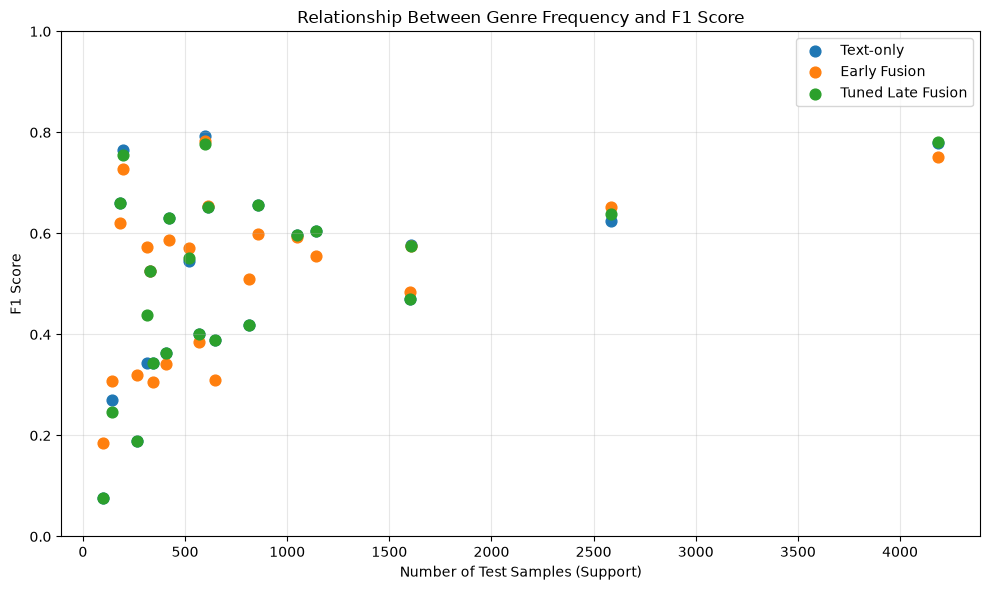

In [461]:
# Plot the relationship between genre support and F1
plt.figure(figsize=(10, 6))

plt.scatter(frequency_results["Support"],
            frequency_results["Text F1"],
            label="Text-only", s=60)

plt.scatter(frequency_results["Support"],
            frequency_results["Early Fusion F1"],
            label="Early Fusion", s=60)

plt.scatter(frequency_results["Support"],
            frequency_results["Late Fusion F1"],
            label="Tuned Late Fusion", s=60)

# Set labels and title
plt.xlabel("Number of Test Samples (Support)")
plt.ylabel("F1 Score")
plt.title("Relationship Between Genre Frequency and F1 Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 14.4.3 Interpret the results

**Genre frequency and model performance**

The results show that some less common genres have low F1 scores. For example, Film-Noir has only 98 test samples, with a Text-only F1 of 0.077, while Musical has 267 samples and an F1 of 0.189. However, genre frequency does not fully explain model performance. Western has only 198 samples but achieves a Text-only F1 of 0.765, while Mystery has 647 samples and a lower F1 of 0.390.

Early Fusion improves performance for some less common genres, particularly Animation (0.344 to 0.574), Musical (0.189 to 0.320) and Film-Noir (0.077 to 0.186). Overall, class imbalance may contribute to poor performance for some genres but the results suggest that other factors, such as genre characteristics and the usefulness of image features, may also affect classification performance

### 14.5 Evaluate robustness to missing modalities

I examine how the Early Fusion model performs when one modality is missing. I test the model using only text features or only image features by replacing the missing features with zeros

I compare the results with the original Early Fusion model using the same test set and prediction threshold of 0.5. This helps assesss how much the model depends on each modality.

#### 14.5.1 Test Early Fusion with missing modalities

In [468]:
# Evaluate Early Fusion when one modality is missing
def evaluate_missing_modality(model, loader, missing_modality):
    model.eval()
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for text_features, image_features, targets in loader:
            text_features = text_features.to(device)
            image_features = image_features.to(device)

            # Replace the missing modality with zeros
            if missing_modality == "image":
                image_features = torch.zeros_like(image_features)

            elif missing_modality == "text":
                text_features = torch.zeros_like(text_features)

            outputs = model(text_features, image_features)
            probabilities = torch.sigmoid(outputs)
            predictions = (probabilities >= 0.5).int()

            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.numpy())

    all_predictions = np.concatenate(all_predictions, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    micro_f1 = f1_score(all_targets, all_predictions,average="micro", zero_division=0)
    macro_f1 = f1_score(all_targets, all_predictions,average="macro", zero_division=0)
    return micro_f1, macro_f1

In [470]:
# Test the Early Fusion model with missing inputs
no_image_micro, no_image_macro = evaluate_missing_modality(early_fusion_model, test_fusion_loader, "image")
no_text_micro, no_text_macro = evaluate_missing_modality(early_fusion_model, test_fusion_loader, "text")

# Compare with the original Early Fusion results
robustness_results = pd.DataFrame({"Input Condition": ["Text + Image",
                                                       "Text Only (Image Missing)",
                                                       "Image Only (Text Missing)"],
                                   "Micro F1": [early_micro_f1,
                                                no_image_micro,
                                                no_text_micro],
                                   "Macro F1": [early_macro_f1,
                                                no_image_macro,
                                                no_text_macro]})
robustness_results.round(4)

,Input Condition,Micro F1,Macro F1
0,Text + Image,0.6044,0.5183
1,Text Only (Image Missing),0.4450,0.3020
2,Image Only (Text Missing),0.2089,0.0940


#### 14.5.2 Visualise and interpret robustness results

I compare Micro F1 and Macro F1 under the three input conditions. This helps show how much the Early Fusion model's performance changes when text or image features are removed

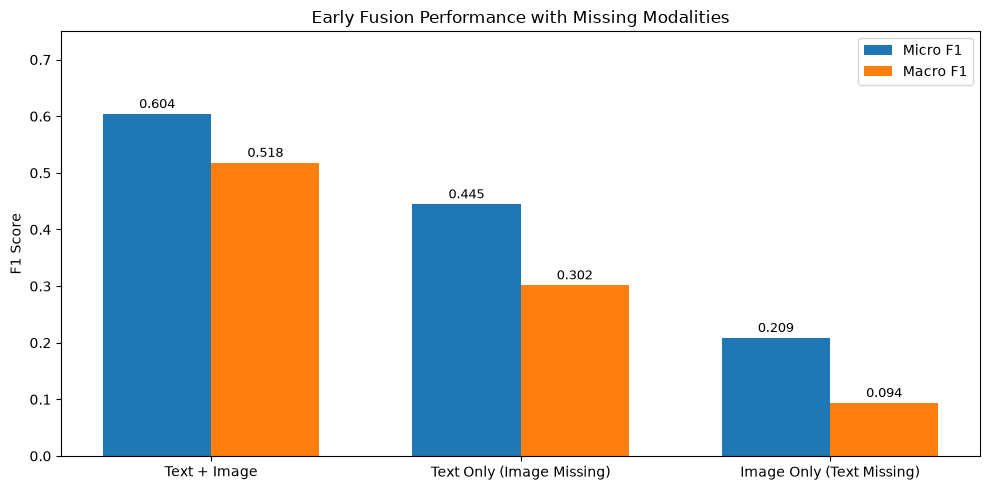

In [473]:
# Plot robustness results for the three input conditions
x = np.arange(len(robustness_results))
width = 0.35
plt.figure(figsize=(10, 5))

micro_bars = plt.bar(x - width / 2,
                     robustness_results["Micro F1"],
                     width,
                     label="Micro F1")
macro_bars = plt.bar(x + width / 2,
                     robustness_results["Macro F1"],
                     width,
                     label="Macro F1")

# Show F1 values above the bars
for bar in list(micro_bars) + list(macro_bars):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.01,
             f"{bar.get_height():.3f}",
             ha="center",
             fontsize=9)

plt.xticks(x, robustness_results["Input Condition"])
plt.ylabel("F1 Score")
plt.title("Early Fusion Performance with Missing Modalities")
plt.ylim(0, 0.75)
plt.legend()
plt.tight_layout()
plt.show()

**Missing modality analysis**

The Early Fusion model achieved its best performance when both text and image features were available with a Micro F1 of 0.6044 and Macro F1 of 0.5183. When image features were replaced with zeros, Micro F1 decreased to 0.4450 and Macro F1 to 0.3020. Removing text features caused a larger drop with Micro F1 falling to 0.2089 and Macro F1 to 0.0940.

These results suggest that the model depends more heavily on text features, although both modalities are important for its performance. The large decrease also shows that the model is sensitive to missing inputs. However, replacing features with zeros is only a simulated missing-modality test. The model was trained using both modalities so these results do not directly represent the performance of separately trained unimodal models.

#### 14.5.3 Save robustness results

In [477]:
# Save robustness results for the final report
robustness_results.to_csv("early_fusion_robustness_results.csv",index=False)
print("Robustness results saved")
print("Number of input conditions:", len(robustness_results))

Robustness results saved
Number of input conditions: 3


## 15. Discussion, Ethical Considerations and Limitations

In this section, I discuss the main findings from the unimodal and multimodal models. I focus on the differences between fusion methods, the limitations of the dataset and models and the ethical issues that should be considered before using the system in practice.


### 15.1 Summarise the main findings

I review the final test results of the five models to identify which approach performs best under Micro F1 and Macro F1. This also helps me discuss whether multimodal fusion provides an improvement over the unimodal baselines.

In [483]:
# Summarise the final test results
discussion_results = final_results.copy()

# Identify the best model for each evaluation metric
best_micro_model = discussion_results.loc[discussion_results["Micro F1"].idxmax(), "Model"]
best_macro_model = discussion_results.loc[discussion_results["Macro F1"].idxmax(), "Model"]
print("Final model comparison:")
display(discussion_results.round(4))

print("\nBest Micro F1 model:", best_micro_model)
print("Best Macro F1 model:", best_macro_model)

Final model comparison:


,Model,Micro F1,Macro F1
0,Text-only,0.6160,0.5078
1,Image-only,0.3830,0.1874
2,Early Fusion,0.6044,0.5183
3,Equal-Weight Late Fusion,0.5122,0.3105
4,Tuned Late Fusion,0.6186,0.5105



Best Micro F1 model: Tuned Late Fusion
Best Macro F1 model: Early Fusion


**Main findings**

Tuned Late Fusion got the best score for Micro F1 (0.6186), whereas Early Fusion performed better in terms of Macro F1 (0.5183). However, the improvements over the Text-only model were small.

The Image-only model performed much worse than the Text-only model, suggesting that plot summaries provide more useful information for this classification task. The Equal-Weight Late Fusion model also performed poorly compared with its tuned version.

In general, multimodal fusion improved performance for some genres, but no fusion model outperformed the Text-only model on both metrics.

### 15.2 Discuss the strengths and limitations of fusion methods

**Early Fusion**

Early Fusion combines text and image features before classification, allowing the model to learn from both inputs together. It obtained the highest Macro F1 (0.5183) and achieved higher F1 scores than Text-only for 9 out of 23 genres. The largest improvement was for Animation, where F1 increased from 0.344 to 0.574. But, the training loss continued to decrease while validation loss increased, suggesting overfitting. Early Fusion also produced more false positives (5633) than the other models

**Late Fusion**

Late Fusion integrates predictions from classifiers that have been trained individually. The approach of giving equal weight to both models was unsuccessful since Image only was less accurate compared to Text only. The weight tuning process for each genre increased the accuracy with the best Micro F1 score of 0.6186. However, most selected weights favoured text, and the improvement over Text-only was small. This suggests that the image modality contributed limited additional information for many genres.

**Comparison**

Early Fusion was more effective under Macro F1, while Tuned Late Fusion achieved better Micro F1. Both methods improved some individual genres, but neither was consistently better than Text-only across both metrics. The results suggest that the choice of fusion method depends on the evaluation objective and the contribution of each modality.

### 15.3 Dataset Bias and Ethical Considerations

The dataset has an imbalanced genre distribution, which may introduce representation bias. For example, Drama accounts for 53.8% of movies, while Film-Noir accounts for only 1.3%. This means the models have fewer examples to learn from for some genres

To examine this issue, I compare the F1 scores of common and less frequent genres. I also discuss how this imbalance may affect the reliability of genre predictions

#### 15.3.1 Examine performance differences across genres

In [530]:
# Compare selected common and less frequent genres
selected_genres = ["Drama", "Comedy", "Animation","Musical", "Short", "Film-Noir"]
# Select the genres and relevant F1 scores
bias_results = late_genre_results[
    late_genre_results["Genre"].isin(selected_genres)][["Genre", "Support", "Text F1","Early Fusion F1", "Late Fusion F1"]].copy()

# Sort by the number of test samples
bias_results = bias_results.sort_values("Support", ascending=False)
display(bias_results.round(3))

,Genre,Support,Text F1,Early Fusion F1,Late Fusion F1
0,Drama,4187,0.778,0.751,0.781
1,Comedy,2586,0.625,0.653,0.638
17,Animation,315,0.344,0.574,0.438
18,Musical,267,0.189,0.320,0.189
21,Short,142,0.271,0.309,0.246
22,Film-Noir,98,0.077,0.186,0.077



#### 15.3.2 Discuss bias and ethical limitations

The results show that some less frequent genres have lower F1 scores. For example, Film-Noir has only 98 positive test samples, with an F1 of 0.077 for Text-only and Tuned Late Fusion. In comparison, Drama has 4187 positive test samples and achieves an F1 of 0.781 with Tuned Late Fusion. However, genre frequency is not the only factor affecting performance. Western has relatively few examples but achieves a high Text-only F1 of 0.765. This suggests that differences in genre characteristics may also influence the results.

Early Fusion improved some less frequent genres, including Animation and Film-Noir but it did not consistently improve all genres. Therefore, multimodal fusion doesn't completely solve the class imbalance problem.

Another limitation is that movie genres can overlap and may involve subjective labelling. Incorrect or inconsistent genre labels could affect model training and evaluation.

The dataset also does not provide enough demographic information to evaluate fairness across different population groups. Therefore, I can't make conclusions about demographic fairness from these experiments.

If this system were used in practice, predictions for less frequent genres should be treated carefully. The model could be used to suggest movie genres but human review would still be useful, especially when predictions are uncertain.

### 15.4 Practical Limitations and Future Improvements

#### 15.4.1 Model limitations

Although the models achieved reasonable results, there are several limitations. First, the Image-only model performed much worse than Text-only with Micro F1 of 0.3830 compared with 0.6160. This suggests that poster images alone provide less useful information for predicting movie genres in this dataset. Second, the Early Fusion model showed signs of overfitting. It's training loss continued to decrease while validation loss increased after the first few epochs. Selecting the best checkpoint using validation Macro F1 helped avoid using the final epoch but it did not completely prevent overfitting. Third, the models were evaluated using one dataset split and a prediction threshold of 0.5. Therefore, the results may change with different data splits or training settings

#### 15.4.2 Robustness and practical use

The missing-modality experiment showed that Early Fusion is sensitive to incomplete inputs. Its Micro F1 decreased from 0.6044 to 0.4450 when image features were removed, and to 0.2089 when text features were removed. This suggest that the model depends more heavily on text information. In practice, missing posters or plot summaries could reduce prediction reliability.

The system also requires feature extraction using DistilBERT and CLIP. Although the extracted features can be saved and reused, processing new movies still requires both encoders. This may increase computational requirements compared with using only one modality.

#### 15.4.3 Future improvements

There are several ways the project could be improved.First, I could test different random seeds or data splits to check whether the results are consistent. Second, I could investigate methods for handling class imbalance to improve predictions for less frequent genres, such as Film-Noir and Short. Third, I could improve robustness by training the fusion model with some missing-modality examples instead of only testing missing inputs after training. Finally, future experiments could compare different fusion settings and evaluate their training time, inference speed and memory requirements more systematically.

#### 15.4.4 Practical recommendations

Based on the results, Text-only would be a reasonable starting point for a movie genre classification system because it achieves strong performance without requiring poster images. If performance across less frequent genres is particularly important, Early Fusion may be considered because it achieved the highest Macro F1 of 0.5183. However, its higher computational requirements and sensitivity to missing modalities should be considered.

Tuned Late Fusion achieved the highest Micro F1 of 0.6186 but its improvement over Text-only was small. Therefore, using both modalities should depend on whether the additional complexity provides enough practical benefit.

### 15.5 Final Conclusion

In this project, I developed and compared five approaches for multi-label movie genre classification using plot summaries and poster images. These included Text-only, Image-only, Early Fusion, Equal-Weight Late Fusion and Tuned Late Fusion.

The results showed that text features were more effective than image features for this dataset. Tuned Late Fusion achieved the highest Micro F1 of 0.6186, while Early Fusion achieved the highest Macro F1 of 0.5183. However, both improvements over the Text-only baseline were relatively small.

The per-genre analysis showed that combining modalities helped some genres, particularly Animation, Musical and Film-Noir under Early Fusion. But, the error analysis and missing-modality experiment also showed that fusion models have limitations, including overfitting and sensitivity to missing inputs.

Overall, this project shows that using both textual and visual information can be helpful in predicting certain movie genres, but it may not always lead to better performance. Therefore, the choice of fusion approach should depend on the evaluation metrics used and the availability of data.

## References
CLIP. (2021). Huggingface.Co. https://huggingface.co/docs/transformers/model_doc/clip 

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2018). BERT: Pre-training of deep bidirectional transformers for language understanding. ArXiv. https://arxiv.org/abs/1810.04805 

Openai/clip-vit-base-patch32 · hugging face. (2021). Huggingface.Co. https://huggingface.co/openai/clip-vit-base-patch32 

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models from natural language supervision. PMLR. Proceedings.Mlr.Press. https://proceedings.mlr.press/v139/radford21a.html

Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: Smaller, faster, cheaper and lighter. arXiv.Org. https://arxiv.org/abs/1910.01108 

Sanh, V., Debut,L., Chaumond,J., & Wolf, T. (2024). Distilbert/distilbert-base-uncased · hugging face. Huggingface.Co. https://huggingface.co/distilbert/distilbert-base-uncased 

Ureña, J. (2024). Simplified MM-IMDb. Kaggledatasets.
https://www.kaggle.com/datasets/javierurea/simplified-mm-imdb 

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., … Rush, A. (2020). Transformers: State-of-the-art natural language processing. Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations, 38‑45. https://doi.org/10.18653/v1/2020.emnlp-demos.6 

